In [ ]:
# import useful libraries
import numpy as np
import matplotlib.pyplot as plt

import os
import sys

# add parent directory to sys.path to import STL package modules
PARENT_DIR = os.path.dirname(os.path.abspath(os.getcwd() + "../../../"))
sys.path.append(PARENT_DIR)
print("Parent directory added to sys.path:", ".../" + PARENT_DIR.split("/")[-1])

# test data directory
DATA_TEST_PATH = PARENT_DIR + "/data" + "/test"
print("Dataset dirctory used:", ".../" + PARENT_DIR.split("/")[-1] + DATA_TEST_PATH.split(PARENT_DIR.split("/")[-1])[-1])

from STL_main.STL_1D_Kernel_Torch import STL_1D_Kernel_Torch
DataClass = STL_1D_Kernel_Torch
from STL_main.Synthesis import synthesize_from_maps
from STL_main.torch_backend import _DEFAULT_DEVICE

print("Working on device:", _DEFAULT_DEVICE)


import torch

Parent directory added to sys.path: .../STL-Dev
Dataset dirctory used: .../STL-Dev/data/test


/Users/richard/Desktop/STL/STL-Dev/STL_main/__init__.py:9: UserWarning: In development mode: Please run 'pip install -e .' in the root directory of the STL repository to properly install the package, its dependencies and enable proper version tracking.
  warnings.warn(


Working on device: mps


In [2]:
# command to auto-reload modules when they are edited (easier for testing and debugging)
%load_ext autoreload
%autoreload 2

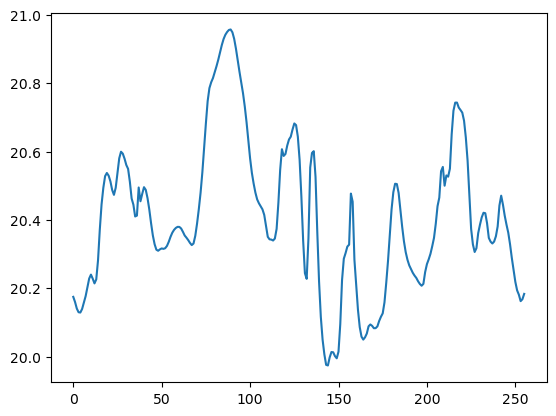

In [3]:
im = np.load(DATA_TEST_PATH + "/" + 'Turb_6.npy')[:,None,:,:]
data = DataClass(im[0,0,0], pbc=True)
plt.plot(data.array.cpu().numpy())

In [4]:
wavelet_op = data.get_wavelet_op()
mean = wavelet_op.mean(data=data)
print("Mean of stl_data_type:", mean)

Mean of stl_data_type: tensor(20.4088, device='mps:0')


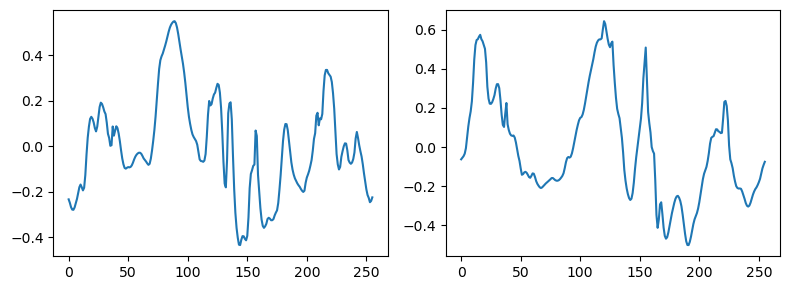

Covariance = tensor(0.0176, device='mps:0')



In [5]:
# Prepare centralized data for covariance tests
stl_data0 = DataClass(im[0,0,0]-im[0,0,0].mean())
stl_data1 = DataClass(im[1,0,0]-im[1,0,0].mean())

# Plot
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes = axes.ravel()
axes[0].plot(stl_data0.array.cpu().numpy())
axes[1].plot(stl_data1.array.cpu().numpy())
plt.tight_layout()
plt.show()

# Test of Cov
cov = wavelet_op.cov(stl_data0, stl_data1)
print("Covariance = " + str(cov))
print()

# test wavelet computation

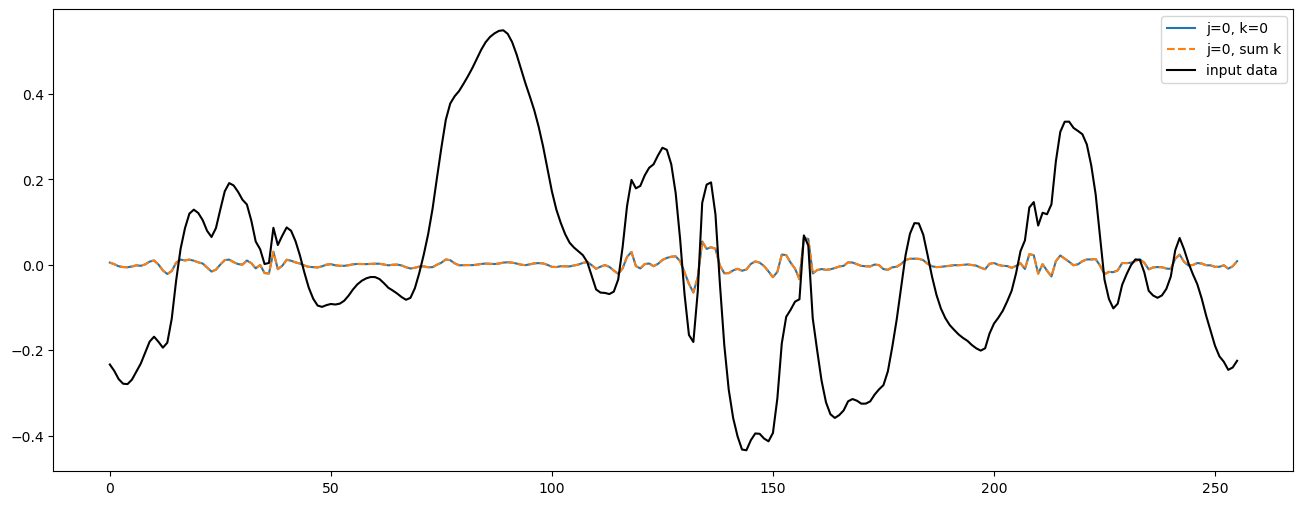

In [6]:
w_op = data.get_wavelet_op(WType="Bump-Steerable")

w_data = w_op.apply(data, j=0)

plt.figure(figsize=(16,6))
for k in range(w_op.L):
    plt.subplot(1,1,1+k)
    plt.plot(w_data.array[k].cpu().numpy().real, label="j=0, k="+str(k))
    plt.plot(w_data.array.sum(axis=0).cpu().numpy().real, label="j=0, sum k", ls='--')
    plt.plot(data.array.cpu().numpy() - data.array.mean().cpu().numpy(), label="input data", c='black')
    plt.legend()

0 6
1 6
2 6
3 6
4 6
5 6


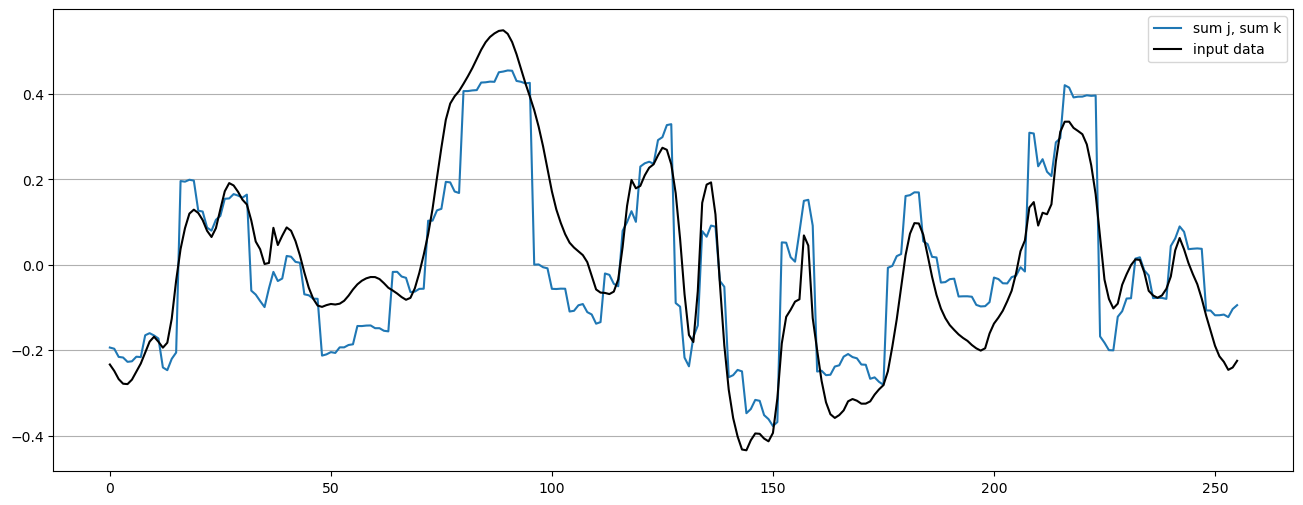

In [8]:
w_op = data.get_wavelet_op(WType="Bump-Steerable")
w_sum = np.zeros_like(data.array.cpu().numpy())

l_data = data.copy()

plt.figure(figsize=(16,6))
for j in range(w_op.J):
    print(j, w_op.J)
    w_data = w_op.apply(l_data, j=j).array.sum(axis=0).cpu().numpy().real
    # oversample w_data by a factor of 2^j
    w_data = np.repeat(w_data, 2**j, axis=0)
    w_sum += w_data
    w_op.downsample(l_data, dg_out=j+1, inplace=True) if j < w_op.J-1 else None

plt.plot(w_sum - w_sum.mean(), label="sum j, sum k")
plt.plot(data.array.cpu().numpy() - data.array.mean().cpu().numpy(), label="input data", c='black')
plt.legend()
plt.grid(True, axis='y')
plt.show()

tensor(20.5145, device='mps:0')


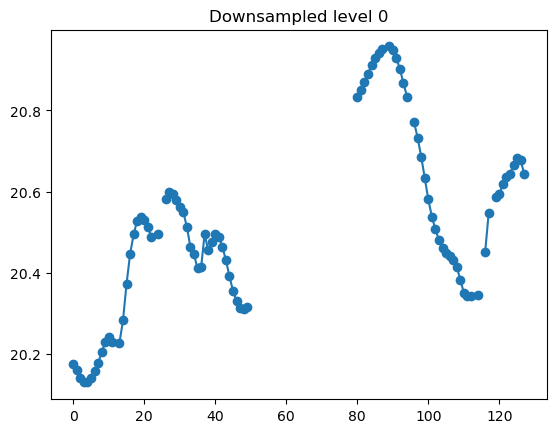

tensor(20.5203, device='mps:0')


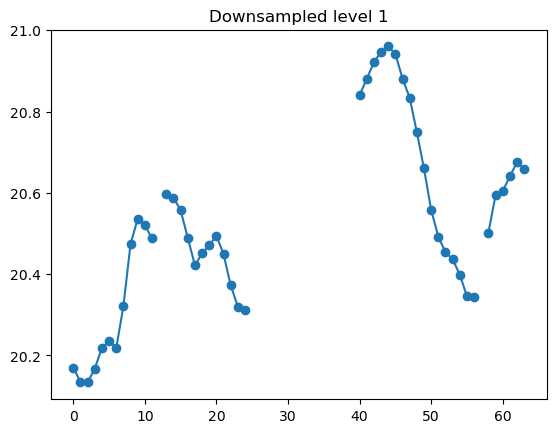

tensor(20.5140, device='mps:0')


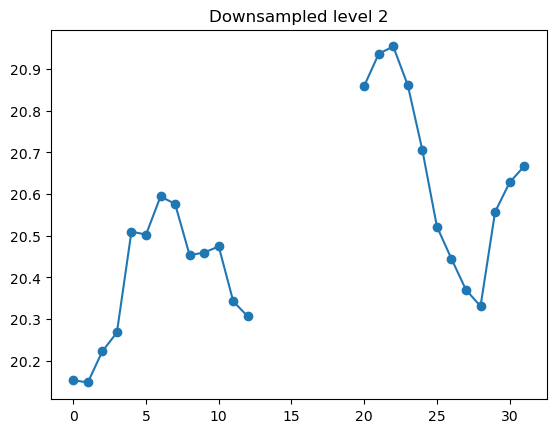

tensor(20.5055, device='mps:0')


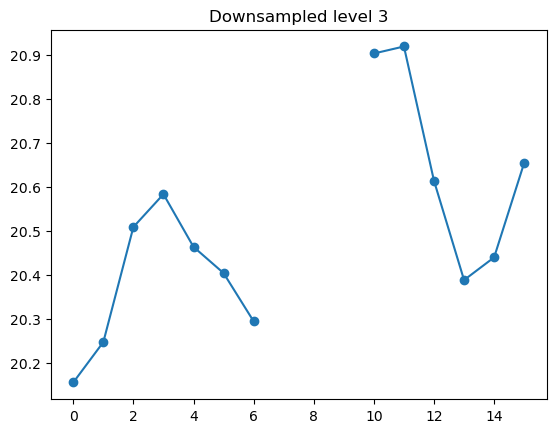

tensor(20.4893, device='mps:0')


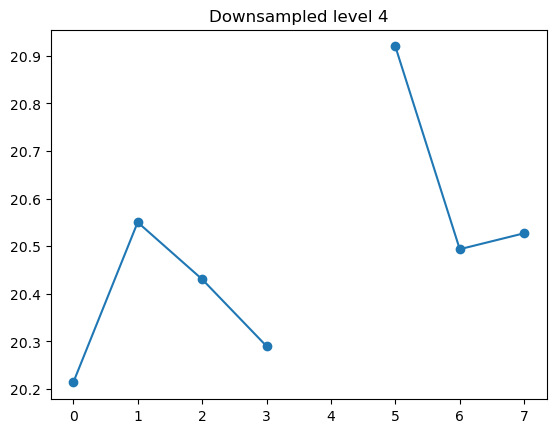

In [9]:
tmp = im[0,0,0].copy()
np.random.seed(32)
tmp[(np.random.rand(25)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:80] = np.nan

l_data = DataClass(tmp[:128], pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)

for dg in range(5):
    print(torch.nanmean(w_op.downsample(l_data, dg_out=dg, inplace=False).array))
    plt.plot(w_op.downsample(l_data, dg_out=dg, inplace=False).array.cpu(), marker='o')
    plt.title("Downsampled level "+str(dg))
    plt.show()

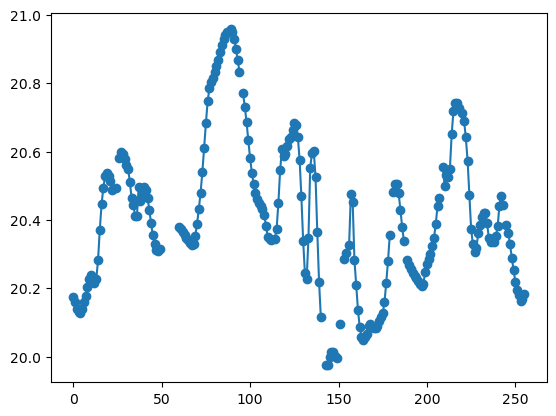

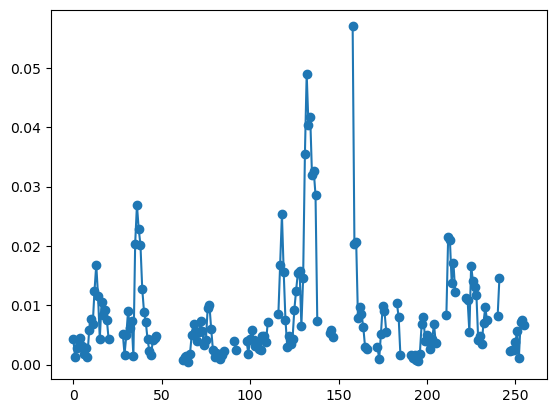

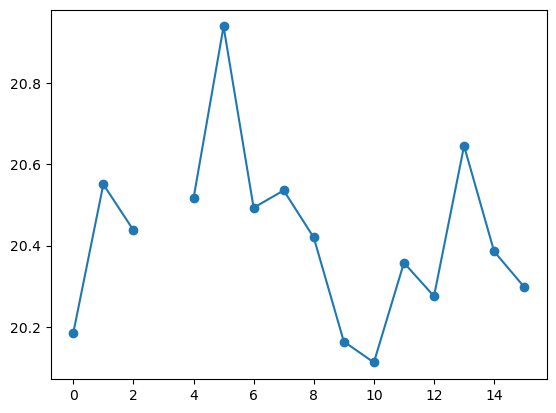

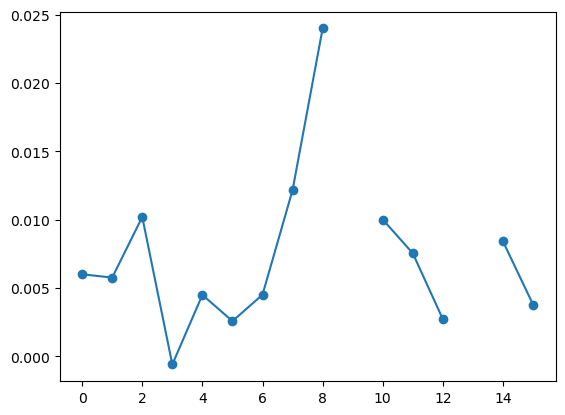

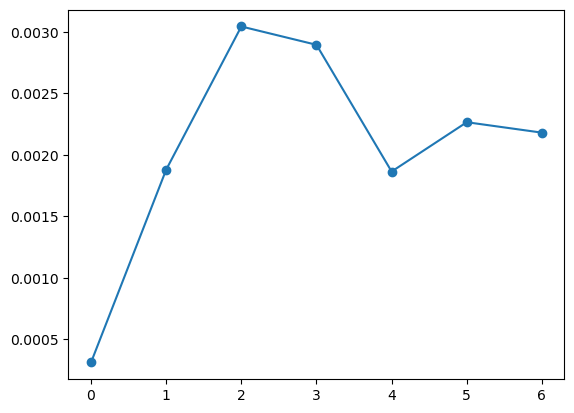

In [10]:
tmp = im[0,0,0].copy()
np.random.seed(32)
tmp[(np.random.rand(17)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:60] = np.nan

plt.plot(tmp, marker='o'), plt.show()

l_data = DataClass(tmp, pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)

w_data = w_op.apply(l_data, j=0)
plt.plot(w_data[0].modulus(inplace=False).array.cpu().numpy(), marker='o'), plt.show()


j = 4

plt.plot(w_op.downsample(l_data, dg_out=j, inplace=False).modulus(inplace=False).array.cpu().numpy(), marker='o'), plt.show()


w_data = w_op.downsample(w_data.modulus(inplace=False), dg_out=j, inplace=True)
plt.plot(w_data[0].array.cpu().numpy(), marker='o'), plt.show()

w_data = w_op.apply(w_data, j=j)
plt.plot(w_data[0,0].modulus().array.cpu().numpy(), marker='o')
plt.show()

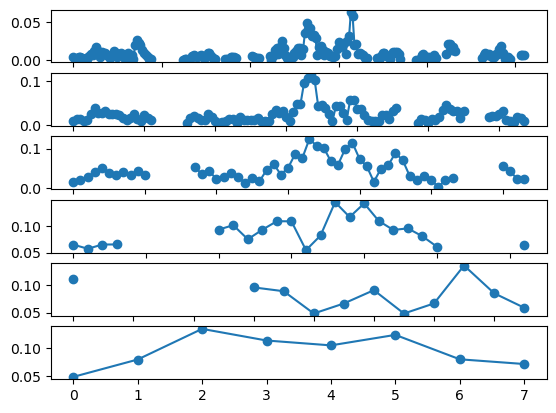

In [11]:
tmp = im[0,0,0].copy()
np.random.seed(27)
tmp[(np.random.rand(17)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:60] = np.nan

l_data = DataClass(tmp, pbc=True)
w_op = l_data.get_wavelet_op(downsample_nan_weight_threshold=0.5)


for j in range(w_op.J):
    w_data = w_op.apply(l_data, j=j)
    for k in range(w_op.L):
        plt.subplot(w_op.J,w_op.L,1+k+w_op.L*j)
        plt.plot(w_data[k].modulus().array.cpu().numpy(), marker='o')
        
    w_op.downsample(l_data, dg_out=j+1, inplace=True) if j < w_op.J-1 else None

In [12]:
l_data = DataClass(im[0,0,0], pbc=True)
l_data_nan = DataClass(tmp, pbc=True)

st_op = l_data.get_ST_op()
st_op_nan = l_data_nan.get_ST_op(downsample_nan_weight_threshold=0.33, 
                                 replace_nan_value=torch.nan)

st_data_nan = st_op_nan.apply(l_data_nan, compute_PS=False)
st_data = st_op.apply(l_data)

/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


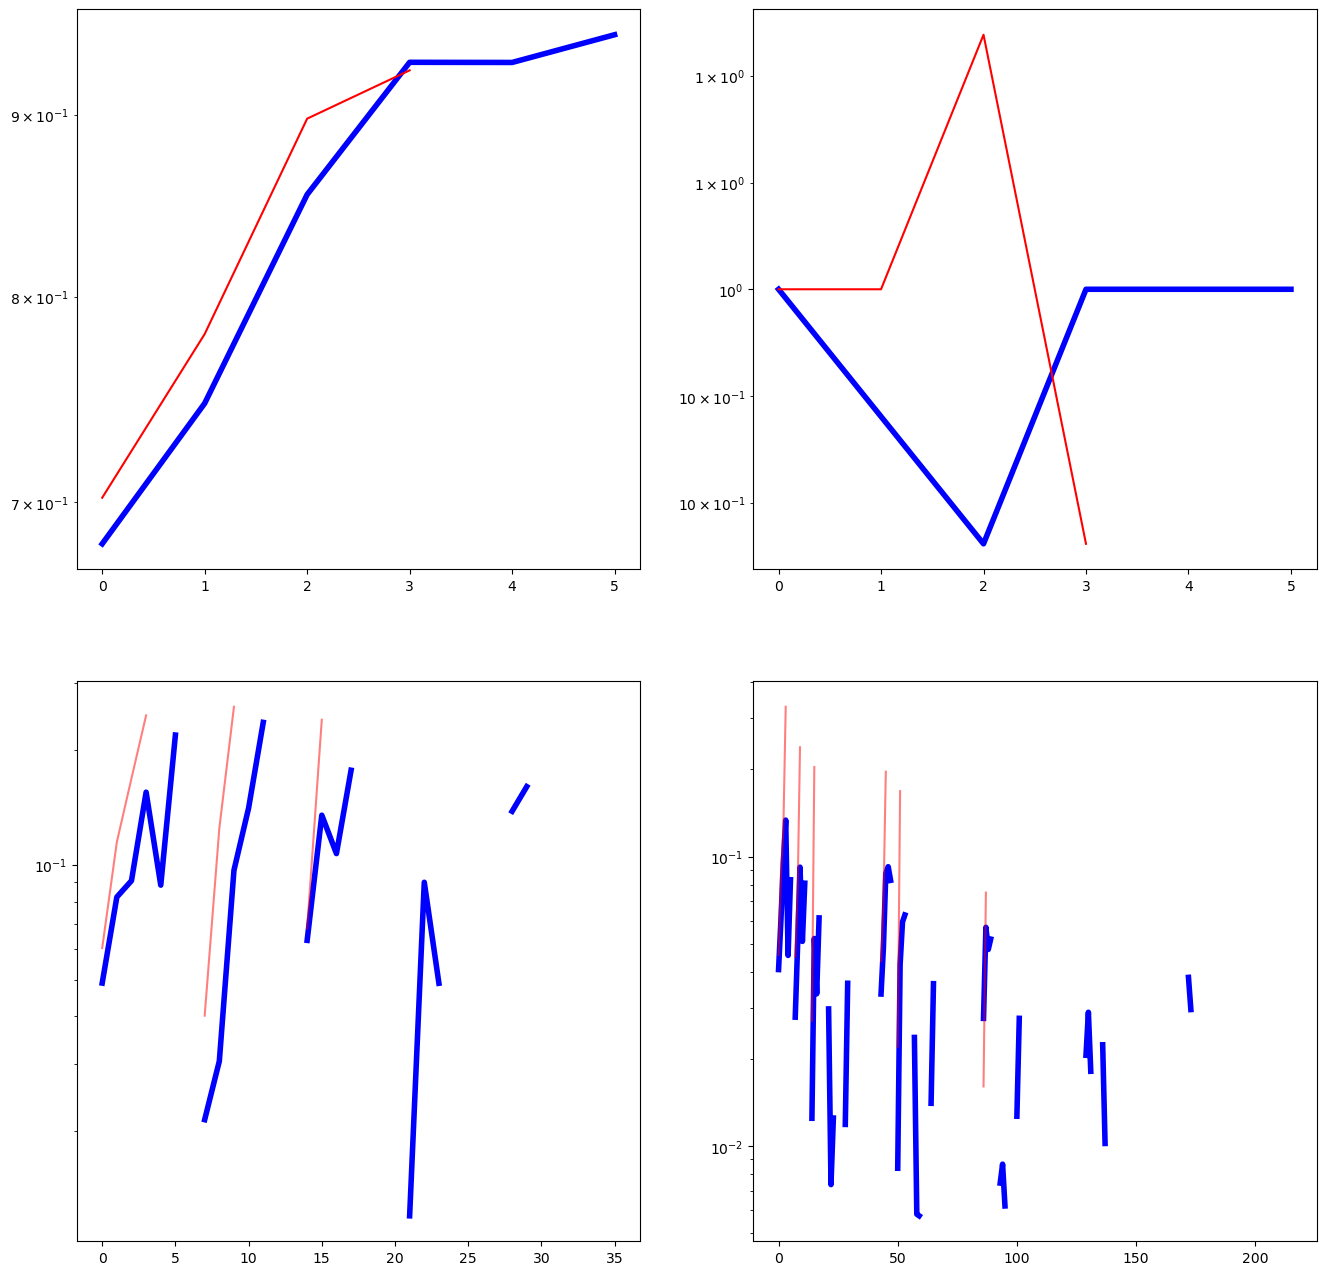

In [13]:
plt.figure(figsize=(16,16))
plt.subplot(2,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S1.cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S2.cpu().numpy().flatten(),color='r')
plt.yscale('log')


plt.subplot(2,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S3.abs().cpu().numpy().flatten(),color='r', alpha=0.5)
plt.yscale('log')
plt.subplot(2,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(),color='b',lw=4)
plt.plot(st_data_nan.S4.cpu().abs().numpy().flatten(),color='r', alpha=0.5)
plt.yscale('log')

# normalization

In [14]:
st_data = st_op.apply(l_data)
st_data_norm = st_op.apply(l_data, norm='store_ref')

Replacing existing var_ref in ST_Op
Replacing existing S2_ref_sqrt_chan_diag in ST_Op
Replacing existing PS_ref_sqrt_chan_diag in ST_Op
Replacing existing var_ref in ST_Op
Replacing existing S2_ref_sqrt_chan_diag in ST_Op
Replacing existing PS_ref_sqrt_chan_diag in ST_Op


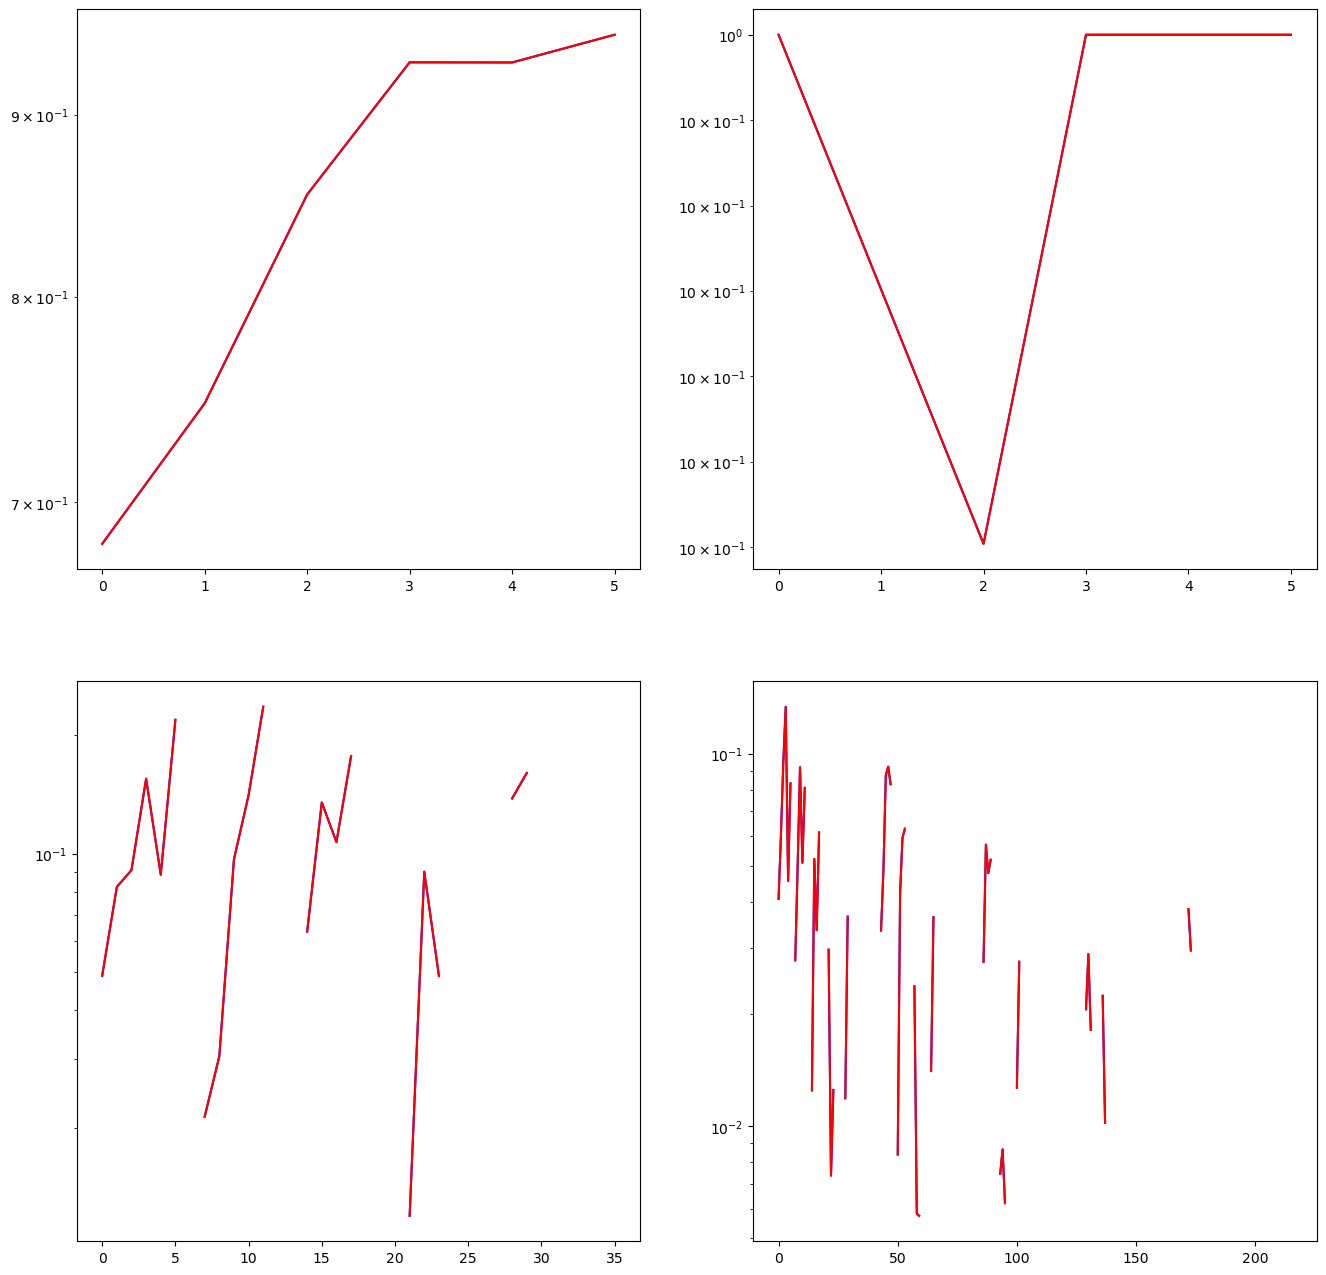

In [15]:
plt.figure(figsize=(16,16))
plt.subplot(2,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S1.cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S2.cpu().numpy().flatten(),color='r')
plt.yscale('log')

plt.subplot(2,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(),color='b')
plt.plot(st_data_norm.S3.abs().cpu().numpy().flatten(),color='r')
plt.yscale('log')
plt.subplot(2,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(),color='b')
plt.plot(st_data_norm.S4.cpu().abs().numpy().flatten(),color='r')
plt.yscale('log')

# PBC = False

Warning! Data with shape (8,) too small to be cropped with border 4. Using border=3 instead.


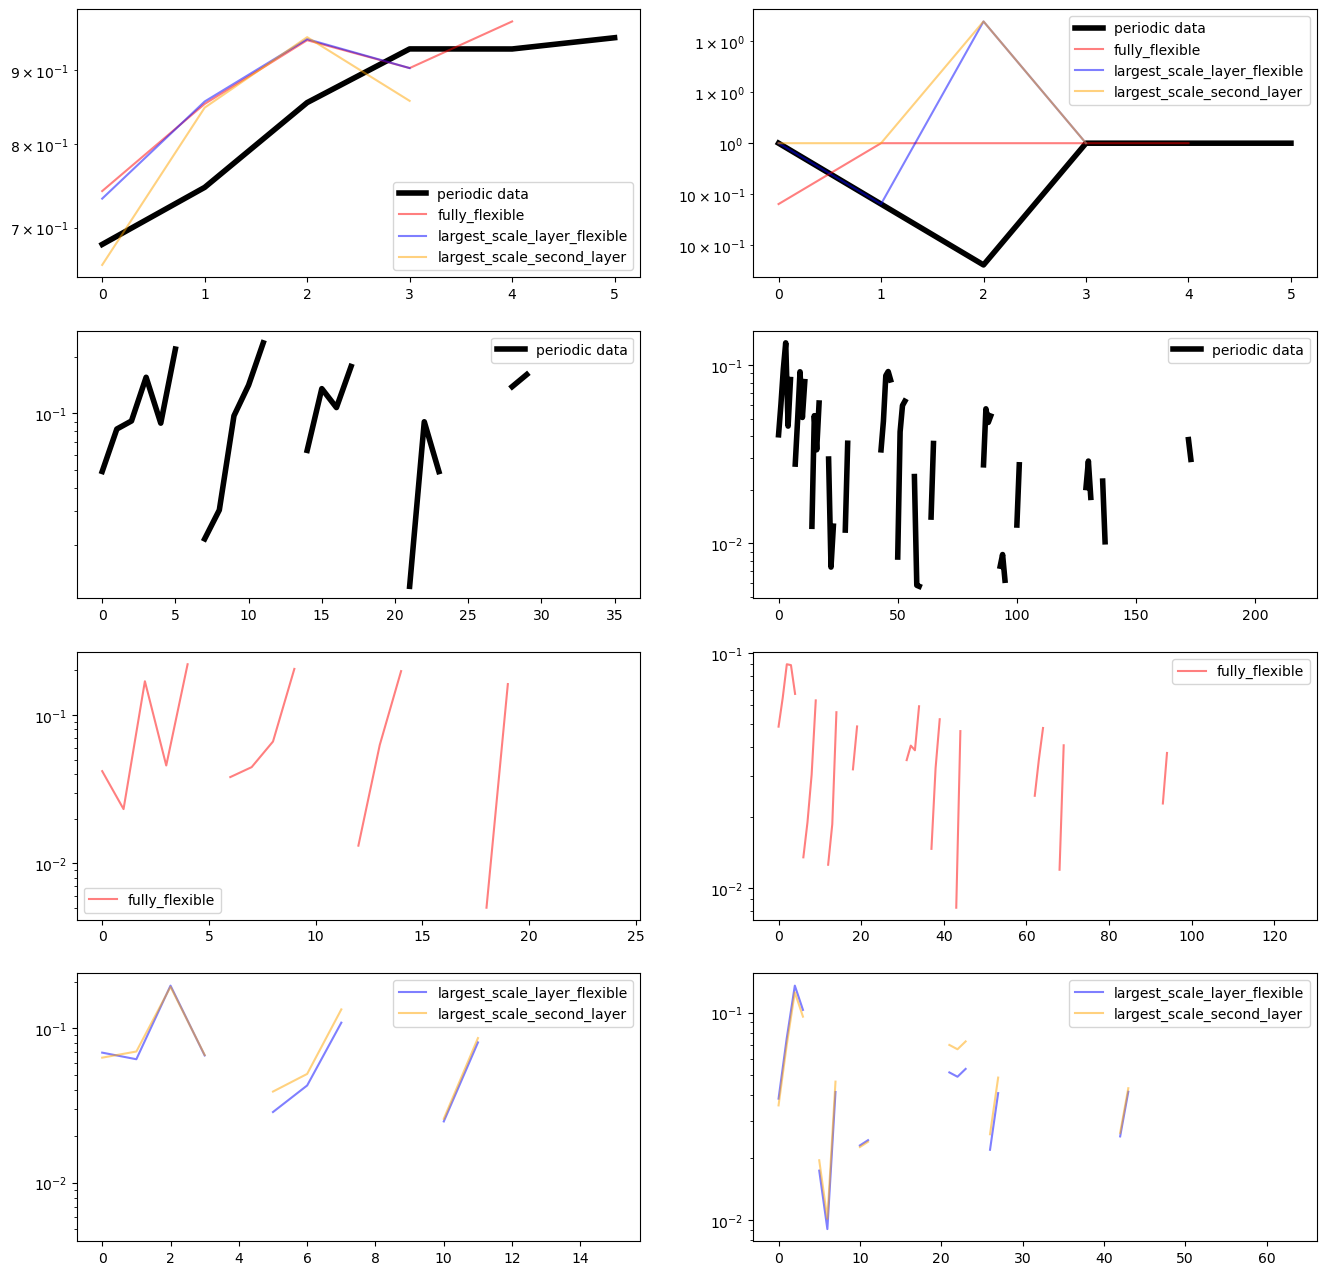

In [16]:
from STL_main.STL_2D_Kernel_Torch import WaveletOperator2Dkernel_torch as WO

l_data = DataClass(im[0,0,0], pbc=True)
l_data_npbc = DataClass(im[0,0,0,:128], pbc=False)

st_op = l_data.get_ST_op()
st_data = st_op.apply(l_data)

plt.figure(figsize=(16,16))

plt.subplot(4,2,1)
plt.plot(st_data.S1.cpu().numpy().flatten(), color='black', lw=4, label='periodic data')

plt.subplot(4,2,2)
plt.plot(st_data.S2.cpu().numpy().flatten(), color='black', lw=4, label='periodic data')

plt.subplot(4,2,3)
plt.plot(st_data.S3.abs().cpu().numpy().flatten(), color='black', lw=4, label='periodic data')
plt.yscale('log')
plt.legend()

plt.subplot(4,2,4)
plt.plot(st_data.S4.cpu().abs().numpy().flatten(), color='black', lw=4, label='periodic data')
plt.yscale('log')
plt.legend()

colors = {'fully_flexible': 'r',
          'largest_scale_layer_flexible': 'blue',
          'largest_scale_second_layer': 'orange'}

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    
    st_op_npbc = l_data_npbc.get_ST_op(
        J=5 if method_name == 'fully_flexible' else 4,
        get_crop_border_size_method=get_crop_border_size_method)
    st_data_npbc = st_op_npbc.apply(l_data_npbc)

    plt.subplot(4,2,1)
    plt.plot(st_data_npbc.S1.cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,2)
    plt.plot(st_data_npbc.S2.cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,7 if method_name != 'fully_flexible' else 5)
    plt.plot(st_data_npbc.S3.abs().cpu().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

    plt.subplot(4,2,8 if method_name != 'fully_flexible' else 6)
    plt.plot(st_data_npbc.S4.cpu().abs().numpy().flatten(),color=colors[method_name], label=method_name, alpha=0.5)
    plt.yscale('log')
    plt.legend()

plt.show()

# simple synthesis

In [17]:
seed = 42

def plot_synthesized_and_target(u, target):

    if u.ndim == 3:
        chan = True
        assert u.shape[1] == 2, "Only 2 channels are supported for plotting"
    else:
        chan = False

    plt.figure(figsize=(10,10))
    plt.subplot(2,2,1)
    if chan:
        plt.plot(u[0,0].cpu().numpy(), label='Channel 1')
        plt.plot(u[0,1].cpu().numpy(), label='Channel 2')
        plt.legend()
    else:
        plt.plot(u[0].cpu().numpy())
    plt.axis('off')
    plt.title('Synthetised #0')

    plt.subplot(2,2,2)
    if chan:
        plt.plot(target[0], label='Channel 1')
        plt.plot(target[1], label='Channel 2')
        plt.legend()
    else:
        plt.plot(target)
    plt.axis('off')
    plt.title('Target')

    fft1 = np.abs(np.fft.fftshift(np.fft.fft(u[0].cpu().numpy(), axis=-1), axes=-1))
    fft2 = np.abs(np.fft.fftshift(np.fft.fft(target, axis=-1), axes=-1))

    q = 1e-2
    vmax = max(np.nanquantile(fft1, 1-q), np.nanquantile(fft2, 1-q))
    vmin = min(np.nanquantile(fft1, q),   np.nanquantile(fft2, q))

    if np.isfinite(vmax):
        plt.figure(figsize=(10,10))
        plt.subplot(2,2,1)

        if np.isfinite(np.nanquantile(fft1, 1-q)):
            if chan:
                plt.plot(fft1[0], label='Channel 1')
                plt.plot(fft1[1], label='Channel 2')
                plt.legend()
            else:
                plt.plot(fft1)
        plt.axis('off')
        plt.yscale('log')
        plt.title('FFT Synthetised #0 Fourier')

        plt.subplot(2,2,2)
        if np.isfinite(np.nanquantile(fft2, 1-q)):
            if chan:
                plt.plot(fft2[0], label='Channel 1')
                plt.plot(fft2[1], label='Channel 2')
                plt.legend()
            else:
                plt.plot(fft2)
        plt.axis('off')
        plt.yscale('log')
        plt.title('Target Fourier')
        plt.show()

    plt.figure(figsize=(16,4))
    for k in range(4):
        plt.subplot(1,4,1+k)
        if chan:
            plt.plot(u[k,0].cpu().numpy(), label='Channel 1')
            plt.plot(u[k,1].cpu().numpy(), label='Channel 2')
            plt.legend()
        else:
            plt.plot(u[k].cpu().numpy())
        plt.axis('off')
        plt.title('Synthetised #%d'%(k))

In [ ]:
u0 = synthesize_from_maps(
    DataClass(im[0,0,0], pbc=True),
    pbc_running=True,
    nbatch=4,
    max_iter=300,
    seed=seed,
)

Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 107 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 1.039332e+03
[LBFGS] iter 20, loss = 1.175796e+01
[LBFGS] iter 30, loss = 6.244271e+00
[LBFGS] iter 40, loss = 2.637410e+00
[LBFGS] iter 50, loss = 1.588388e+00
[LBFGS] iter 60, loss = 1.158352e+00
[LBFGS] iter 70, loss = 8.345864e-01
[LBFGS] iter 80, loss = 5.989736e-01
[LBFGS] iter 90, loss = 4.410070e-01
[LBFGS] iter 100, loss = 3.396850e-01
[LBFGS] iter 110, loss = 2.468471e-01
[LBFGS] iter 120, loss = 1.747491e-01
[LBFGS] iter 130, loss = 1.277215e-01
[LBFGS] iter 140, loss = 9.808611e-02
[LBFGS] iter 150, loss = 8.110686e-02
[LBFGS] iter 160, loss = 6.706648e-02
[LBFGS] iter 170, loss = 5.726144e-02
[LBFGS] iter 180, loss = 4.930809e-02
[LBFGS] iter 190, loss = 4.328876e-02
[LBFGS] iter 200, loss = 3.667567e-02
[LBFGS] it

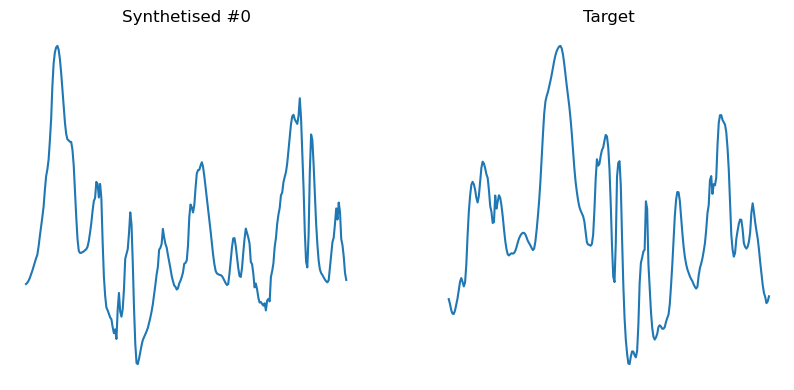

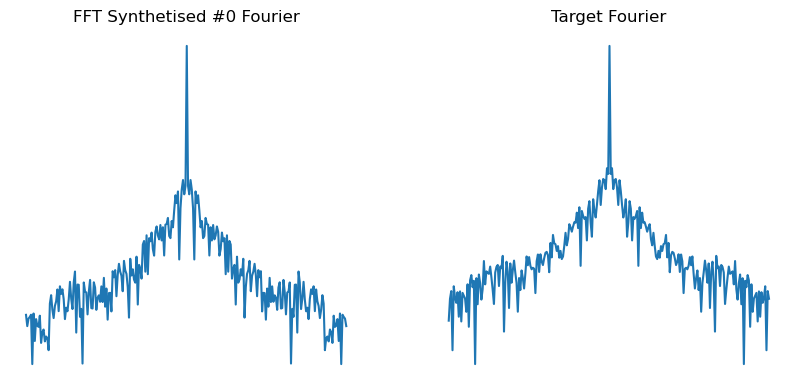

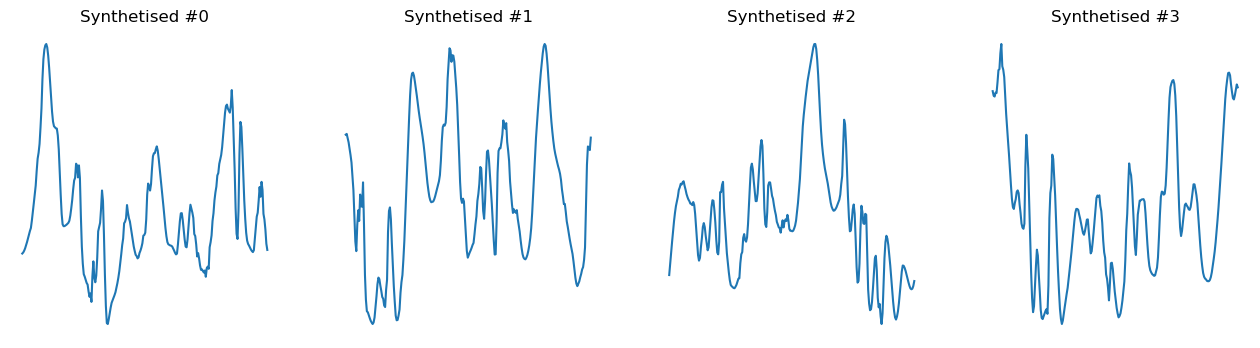

In [19]:
plot_synthesized_and_target(u0[:,:], im[0,0,0])

# multichannel synthesis

In [20]:
target_multi = np.stack([im[0,0,0], (im[0,0,0]-im[0,0,0].mean(keepdims=True))**2])
target_multi -= target_multi.mean(axis=(-1,), keepdims=True)
target_multi = DataClass(target_multi, pbc=True)
st_op = target_multi.get_ST_op()

In [21]:
compute_cross_matrix = torch.tensor([[1, 1], [0, 1]], dtype=torch.bool)
compute_cross_matrix

tensor([[ True,  True],
        [False,  True]])

In [26]:
u1 = synthesize_from_maps(
        data_target=target_multi,
        pbc_running=True,
        compute_cross_matrix=compute_cross_matrix,        
        compute_PS=False,
        nbatch=4,
        max_iter=400,
        seed=seed,
    )

Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 2, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 348 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 2.256320e+02
[LBFGS] iter 20, loss = 3.427435e+01
[LBFGS] iter 30, loss = 2.073870e+01
[LBFGS] iter 40, loss = 1.069022e+01
[LBFGS] iter 50, loss = 5.288915e+00
[LBFGS] iter 60, loss = 3.613346e+00
[LBFGS] iter 70, loss = 2.556876e+00
[LBFGS] iter 80, loss = 1.928120e+00
[LBFGS] iter 90, loss = 1.505792e+00
[LBFGS] iter 100, loss = 1.218306e+00
[LBFGS] iter 110, loss = 9.962107e-01
[LBFGS] iter 120, loss = 8.452521e-01
[LBFGS] iter 130, loss = 7.115786e-01
[LBFGS] iter 140, loss = 6.086833e-01
[LBFGS] iter 150, loss = 5.155351e-01
[LBFGS] iter 160, loss = 4.452651e-01
[LBFGS] iter 170, loss = 3.869757e-01
[LBFGS] iter 180, loss = 3.417193e-01
[LBFGS] iter 190, loss = 3.055851e-01
[LBFGS] iter 200, loss = 2.714119e-01
[LBFGS] it

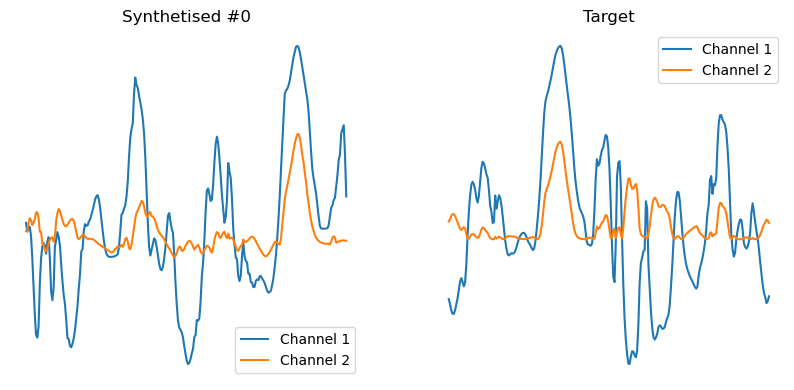

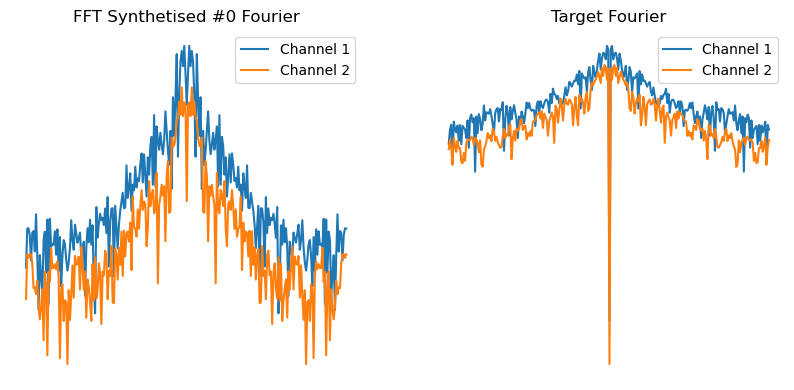

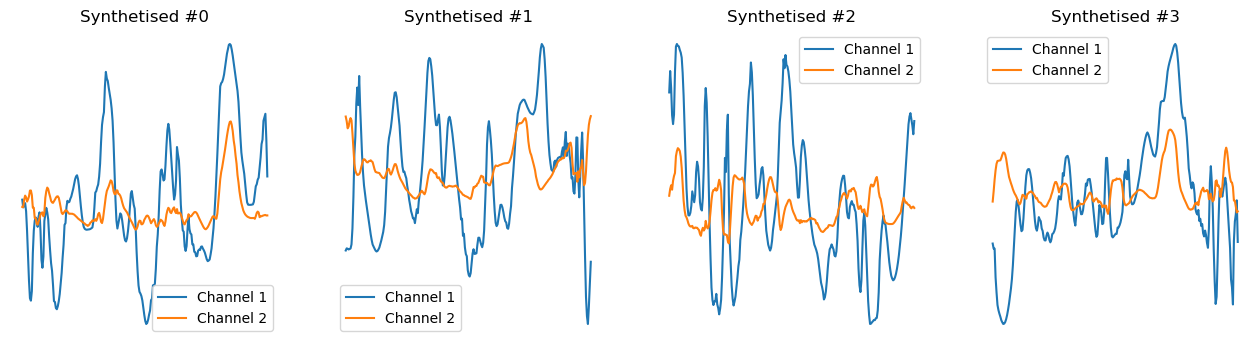

In [27]:
plot_synthesized_and_target(u1[:,:], target_multi.array.cpu().numpy())

# Synthesis with NaNs

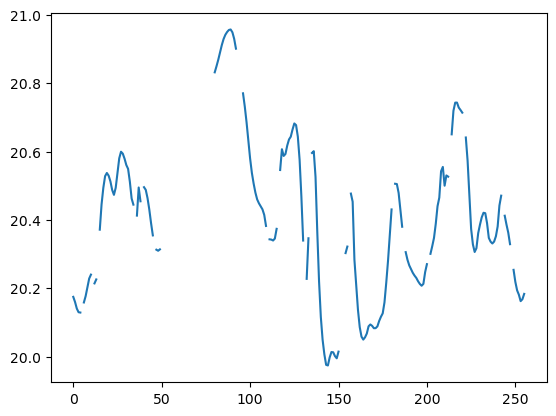

In [28]:
tmp = im[0,0,0].copy()
np.random.seed(seed)
tmp[(np.random.rand(30)*tmp.shape[0]).astype('int')] = np.nan
tmp[50:80] = np.nan
plt.plot(tmp)
plt.show()

## Running without NaNs

In [29]:
target = DataClass(tmp, pbc=True)

u2 = synthesize_from_maps(
        data_target=target,
        pbc_running=True,
        nbatch=4,
        max_iter=300,
        seed=seed,
    )

⚠️ Warning: NaN detected in target and/or running data.
Power spectrum optimization is disabled because its computation is not yet implemented for NaN values in any dataclass. 

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256)
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account
[LBFGS] iter 10, loss = 1.390616e+03
[LBFGS] iter 20, loss = 4.913581e+01
[LBFGS] iter 30, loss = 2.330343e+01
[LBFGS] iter 40, loss = 1.515012e+01
[LBFGS] iter 50, loss = 1.223418e+01
[LBFGS] iter 60, loss = 1.026636e+01
[LBFGS] iter 70, loss = 8.558020e+00
[LBFGS] iter 80, loss = 6.967726e+00
[LBFGS] iter 90, loss = 5.399478e+00
[LBFGS] iter 100, loss = 4.394498e+00
[LBFGS] iter 110, loss = 3.668704e+00
[LBFGS] iter 120, loss = 3.318994e+00
[LBFGS] iter 130, loss = 2.615902e+00
[LBFGS] ite

/Users/richard/miniconda3/envs/gpu310/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1601: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


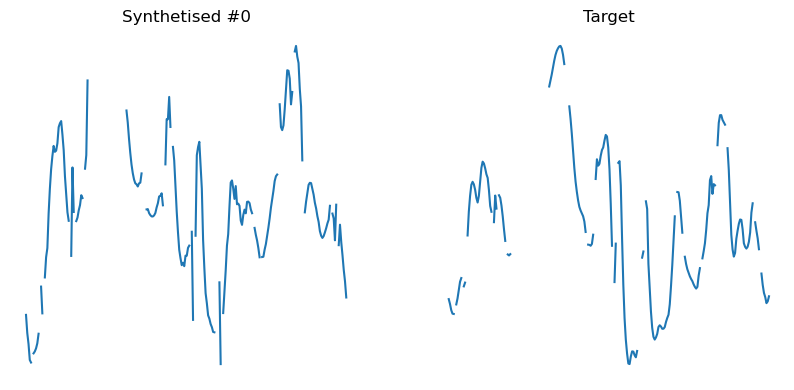

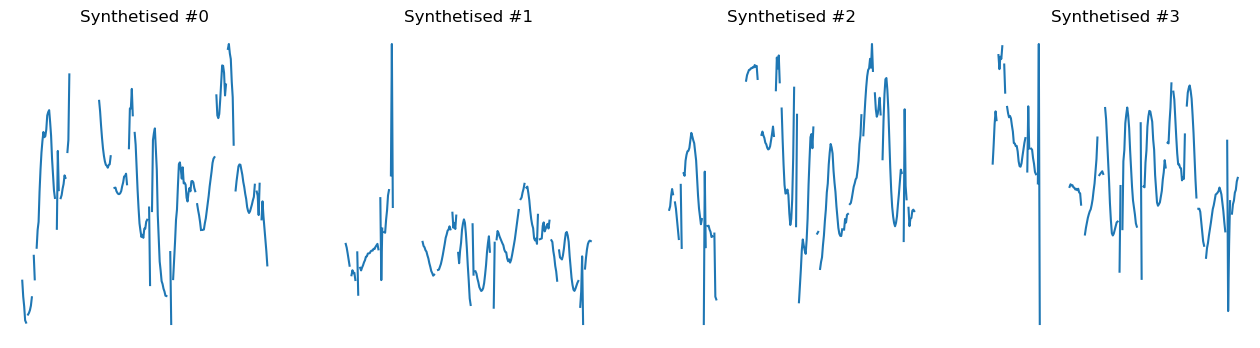

In [30]:
plot_synthesized_and_target(u2, target.array.cpu().numpy())

## Running with same NaN mask as target

In [31]:
u3 = synthesize_from_maps(
        data_target=target,
        pbc_running=True,
        nbatch=4,
        max_iter=300,
        seed=seed,
    )

⚠️ Warning: NaN detected in target and/or running data.
Power spectrum optimization is disabled because its computation is not yet implemented for NaN values in any dataclass. 

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256)
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account
[LBFGS] iter 10, loss = 1.390616e+03
[LBFGS] iter 20, loss = 4.913581e+01
[LBFGS] iter 30, loss = 2.330343e+01
[LBFGS] iter 40, loss = 1.515012e+01
[LBFGS] iter 50, loss = 1.223418e+01
[LBFGS] iter 60, loss = 1.026636e+01
[LBFGS] iter 70, loss = 8.558020e+00
[LBFGS] iter 80, loss = 6.967726e+00
[LBFGS] iter 90, loss = 5.399478e+00
[LBFGS] iter 100, loss = 4.394498e+00
[LBFGS] iter 110, loss = 3.668704e+00
[LBFGS] iter 120, loss = 3.318994e+00
[LBFGS] iter 130, loss = 2.615902e+00
[LBFGS] ite

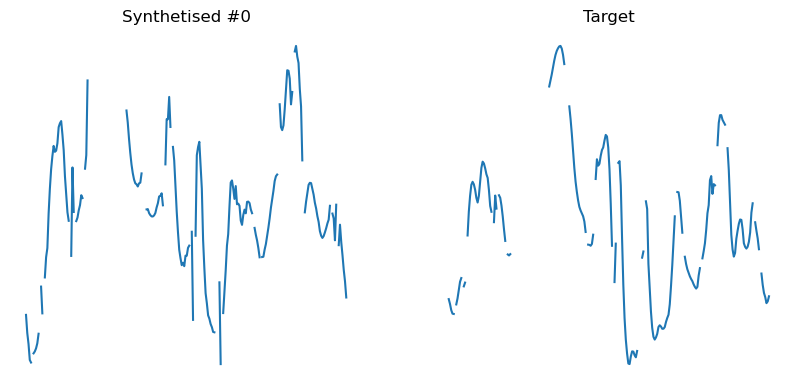

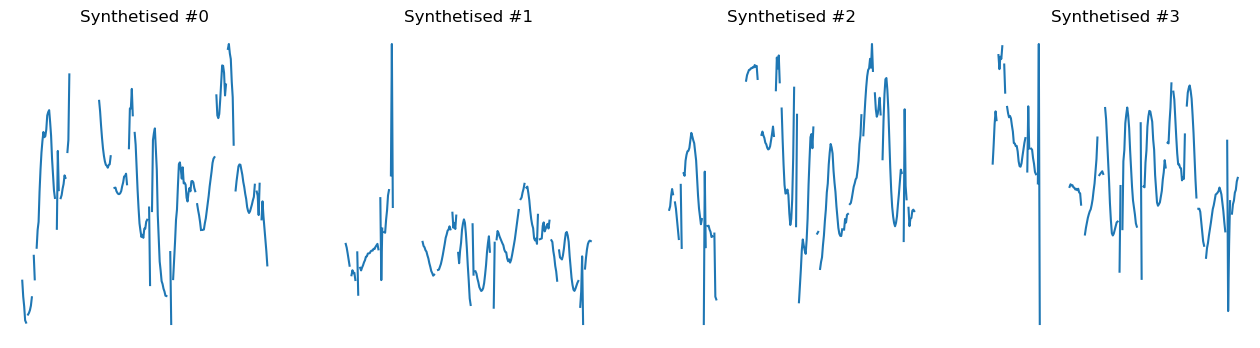

In [32]:
plot_synthesized_and_target(u3, tmp)

## Running with new NaN mask

In [33]:
new_mask = np.zeros_like(im[0,0,0])
new_mask[150:175] = np.nan

In [34]:
u4 = synthesize_from_maps(
        data_target=target,
        pbc_running=True,
        nbatch=4,
        max_iter=300,
        seed=seed,
    )

⚠️ Warning: NaN detected in target and/or running data.
Power spectrum optimization is disabled because its computation is not yet implemented for NaN values in any dataclass. 

Running synthesis on device: mps:0 dtype: torch.float32
NaN detected in the target, the synthesis takes it into account
Initial shape for u: (4, 1, 256)
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
NaN detected in the running synthesis mask, the synthesis takes it into account
[LBFGS] iter 10, loss = 1.390616e+03
[LBFGS] iter 20, loss = 4.913581e+01
[LBFGS] iter 30, loss = 2.330343e+01
[LBFGS] iter 40, loss = 1.515012e+01
[LBFGS] iter 50, loss = 1.223418e+01
[LBFGS] iter 60, loss = 1.026636e+01
[LBFGS] iter 70, loss = 8.558020e+00
[LBFGS] iter 80, loss = 6.967726e+00
[LBFGS] iter 90, loss = 5.399478e+00
[LBFGS] iter 100, loss = 4.394498e+00
[LBFGS] iter 110, loss = 3.668704e+00
[LBFGS] iter 120, loss = 3.318994e+00
[LBFGS] iter 130, loss = 2.615902e+00
[LBFGS] ite

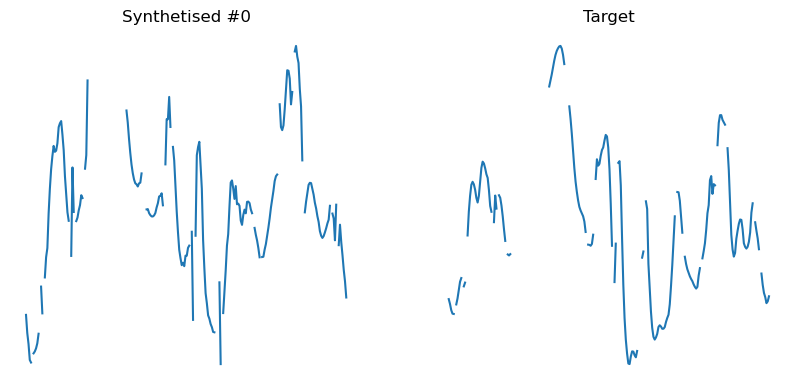

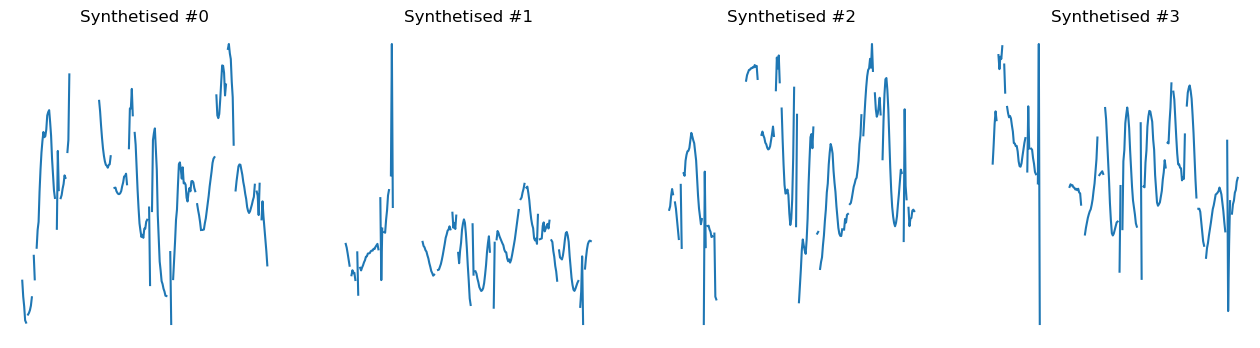

In [35]:
plot_synthesized_and_target(u4, tmp)

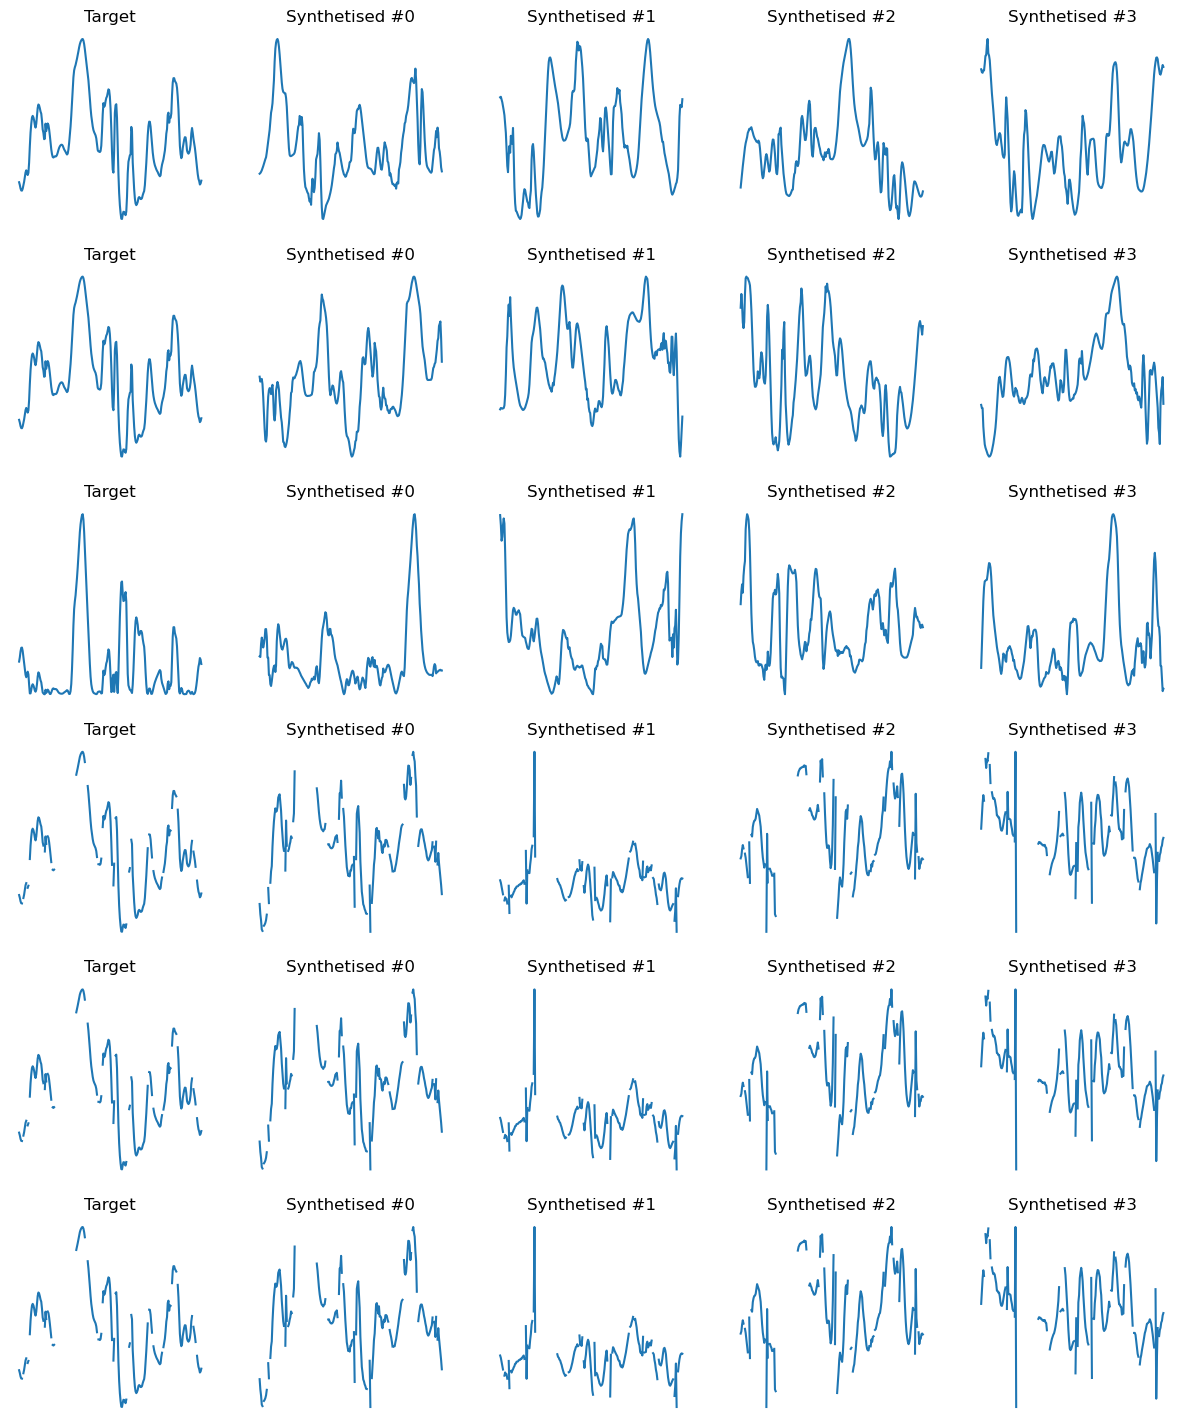

In [36]:
plt.figure(figsize=(5*3, 6*3))
for ind, (u, tgt) in enumerate(zip([u0, u1[:,0], u1[:,1], u2, u3, u4], [im[0,0,0], target_multi.array[0].cpu().numpy(), target_multi.array[1].cpu().numpy(), tmp, tmp, tmp])):
    plt.subplot(6,5,1 + ind*5)
    plt.plot(tgt), plt.axis('off')
    plt.title('Target')
    for k in range(4):
        plt.subplot(6,5,2 + k + ind*5)
        plt.plot(u[k].cpu().numpy())
        plt.title('Synthetised #%d'%(k))
        plt.axis('off')

if False:
    plt.savefig("nan_synthesis.png", bbox_inches='tight', dpi=100)

# synthesis with PBC = False 

In [37]:
synthesis_target_npbc_results = {}

target = DataClass(im[0,0,0,:128], pbc=False)

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    print(method_name)
    J = 5 if method_name == 'fully_flexible' else 4

    u = optimize_from_maps(
            target=target,
            st_op_target=target.get_ST_op(
                J=J,
                get_crop_border_size_method=get_crop_border_size_method),
            st_op_running=DataClass(im[0,0,0,:128], pbc=True).get_ST_op(J=J),
            pbc_running=True,
            nbatch=4,
            max_iter=300,
            prefilter_Nyquist=True,
            lr=1.0,
            history_size=50,
            print_iter=10,
            verbose=True,
            seed=seed,
        )

    synthesis_target_npbc_results[method_name] = u

fully_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128)
Prefiltering target to remove frequencies above Nyquist
Warning! Data with shape (8,) too small to be cropped with border 4. Using border=3 instead.
Synthesis on 62 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 2.489116e+02
[LBFGS] iter 20, loss = 6.188714e+00
[LBFGS] iter 30, loss = 4.618313e+00
[LBFGS] iter 40, loss = 3.585648e+00
[LBFGS] iter 50, loss = 2.539965e+00
[LBFGS] iter 60, loss = 1.681419e+00
[LBFGS] iter 70, loss = 1.229545e+00
[LBFGS] iter 80, loss = 8.786498e-01
[LBFGS] iter 90, loss = 6.115978e-01
[LBFGS] iter 100, loss = 4.467463e-01
[LBFGS] iter 110, loss = 3.339532e-01
[LBFGS] iter 120, loss = 2.458462e-01
[LBFGS] iter 130, loss = 1.795371e-01
[LBFGS] iter 140, loss = 1.402129e-01
[LBFGS] iter 150, loss = 1.162223e-01
[LBFGS] iter 160, loss = 9.805910e-02
[LBFGS] iter 170, loss = 8.192004e-02
[LBFGS] iter 180,

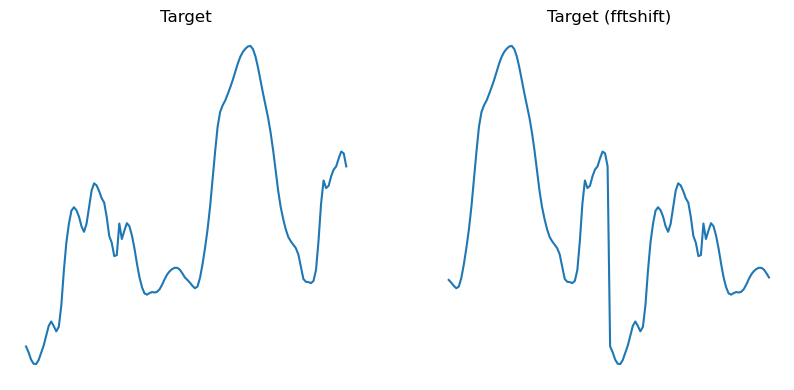

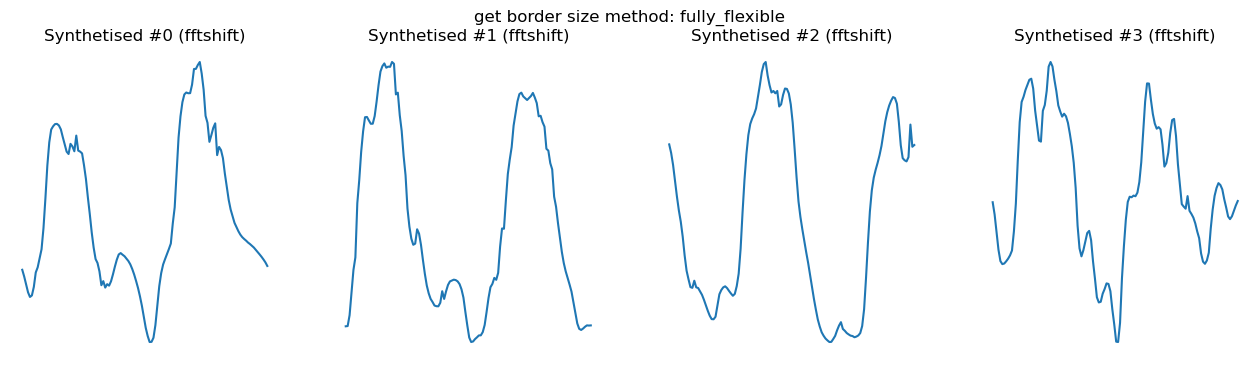

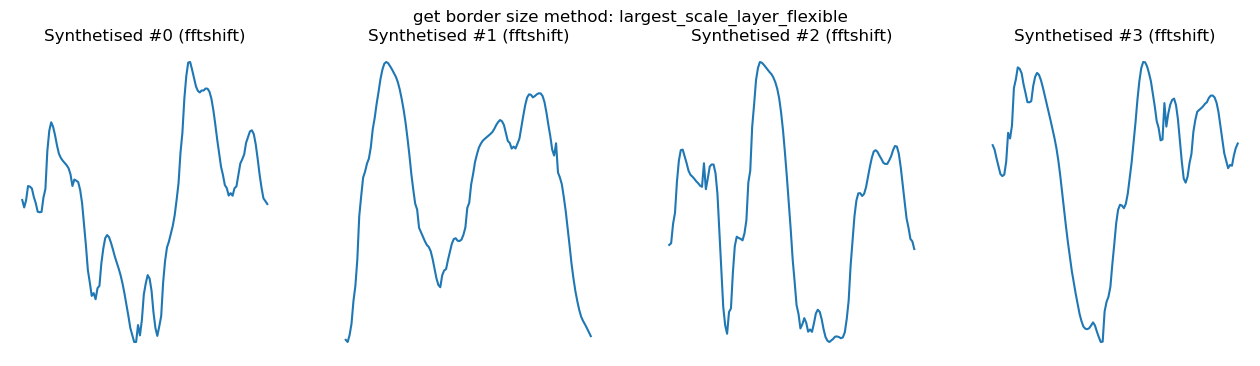

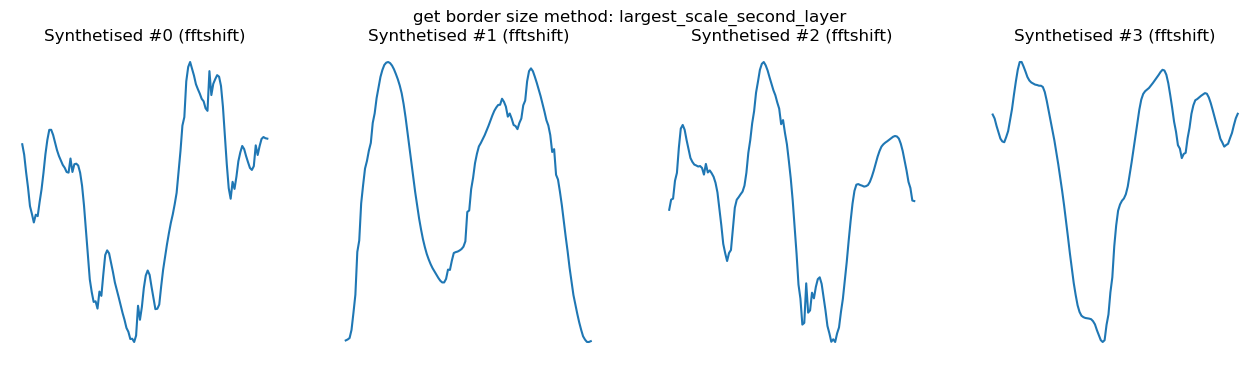

In [38]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.plot(np.fft.fftshift(im[0,0,0,:128]))
plt.axis('off')
plt.title('Target (fftshift)')

for method_name, u in synthesis_target_npbc_results.items():

    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.plot(np.fft.fftshift(u[k].cpu().numpy()))
        plt.axis('off')
        plt.title('Synthetised #%d (fftshift)'%(k))

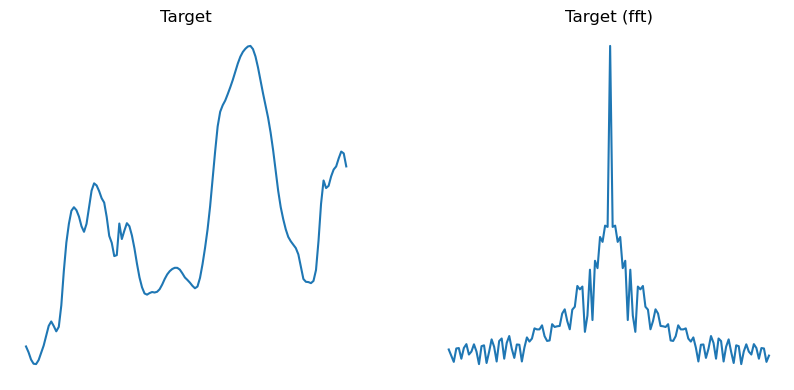

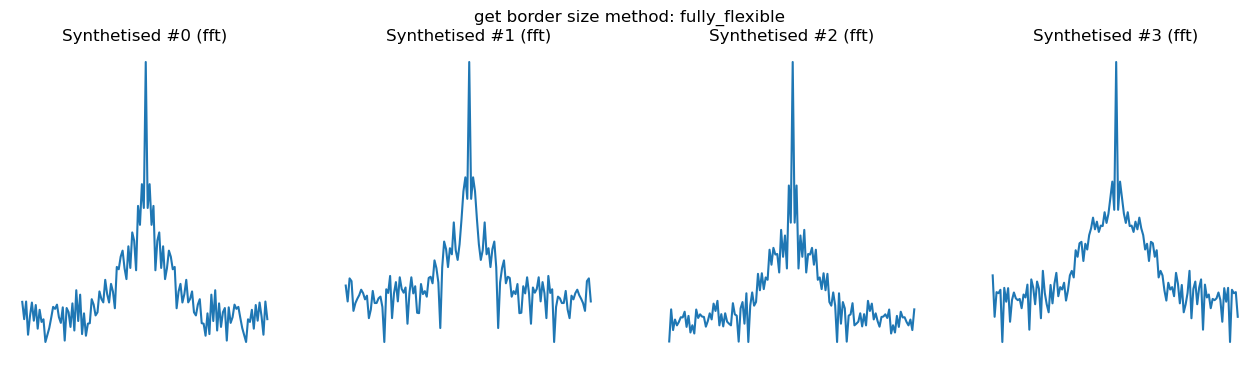

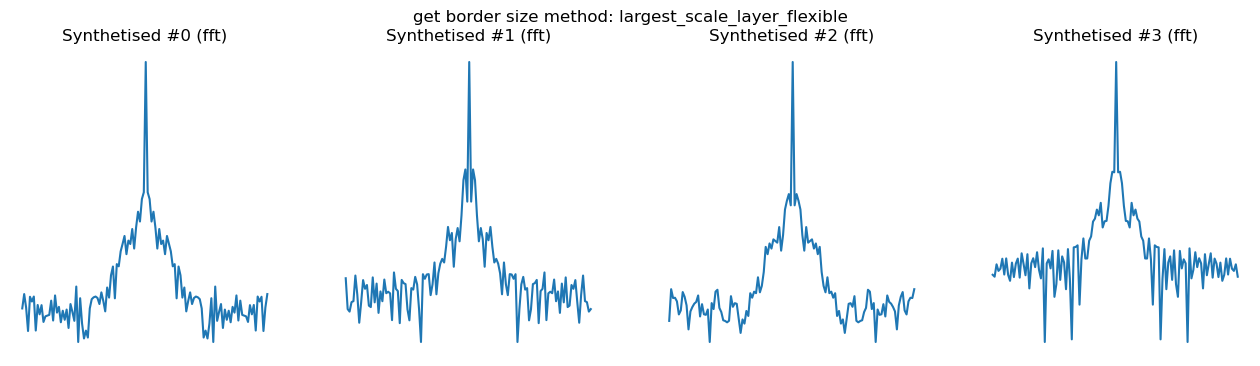

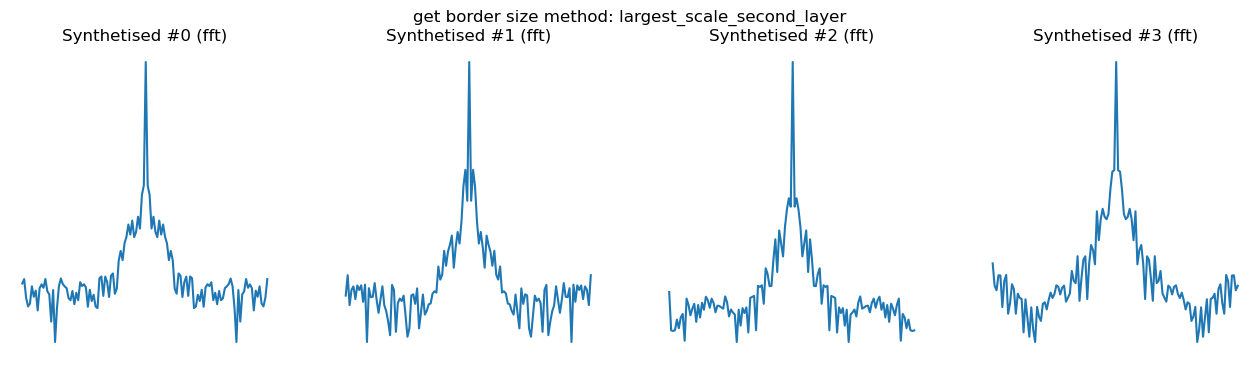

In [39]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(im[0,0,0,:128]))))
plt.axis('off')
plt.title('Target (fft)')

for method_name, u in synthesis_target_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(u[k].cpu().numpy()))))
        plt.axis('off')
        plt.title('Synthetised #%d (fft)'%(k))

In [40]:
synthesis_target_running_npbc_results = {}

target = DataClass(im[0,0,0,:128], pbc=False)

for method_name, get_crop_border_size_method in zip(['fully_flexible', 
                                                     'largest_scale_layer_flexible', 
                                                     'largest_scale_second_layer'],
                                                    [WO._get_crop_border_size_fully_flexible,
                                                     WO._get_crop_border_size_largest_scale_layer_flexible,
                                                     WO._get_crop_border_size_largest_scale_second_layer]):
    print(method_name)
    J = 5 if method_name == 'fully_flexible' else 4

    st_op = target.get_ST_op(J=J, get_crop_border_size_method=get_crop_border_size_method)

    u = optimize_from_maps(
            target=target,
            st_op_target=st_op,
            st_op_running=st_op,
            pbc_running=False,
            nbatch=4,
            max_iter=300,
            lr=1.0,
            history_size=50,
            print_iter=10,
            verbose=True,
            seed=seed,
        )

    synthesis_target_running_npbc_results[method_name] = u

fully_flexible
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 128)
Prefiltering target to remove frequencies above Nyquist
Warning! Data with shape (8,) too small to be cropped with border 4. Using border=3 instead.
Synthesis on 62 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
[LBFGS] iter 10, loss = 2.994622e+02
[LBFGS] iter 20, loss = 5.631085e+00
[LBFGS] iter 30, loss = 4.337252e+00
[LBFGS] iter 40, loss = 3.420424e+00
[LBFGS] iter 50, loss = 2.444826e+00
[LBFGS] iter 60, loss = 1.661956e+00
[LBFGS] iter 70, loss = 1.278262e+00
[LBFGS] iter 80, loss = 9.633286e-01
[LBFGS] iter 90, loss = 7.069468e-01
[LBFGS] iter 100, loss = 4.939843e-01
[LBFGS] iter 110, loss = 3.551063e-01
[LBFGS] iter 120, loss = 2.599095e-01
[LBFGS] iter 130, loss = 1.884559e-01
[LBFGS] iter 140, loss = 1.407384e-01
[LBFGS] iter 150, loss = 1.026216e-01
[LBFGS] iter 160, loss = 7.941655e-02
[LBFGS] iter 170, loss = 6.082575e-02
[LBFGS] iter 180,

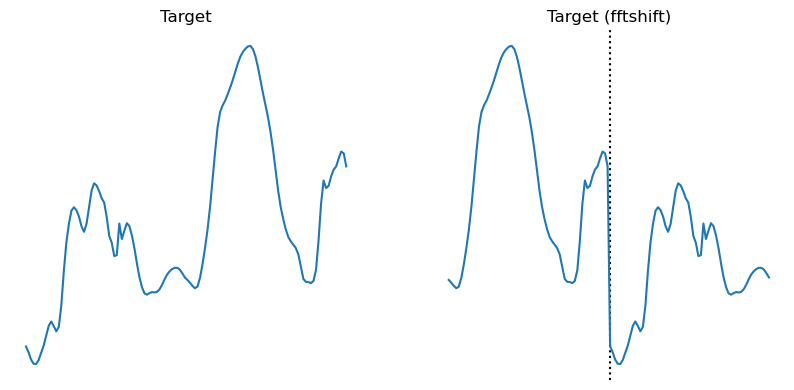

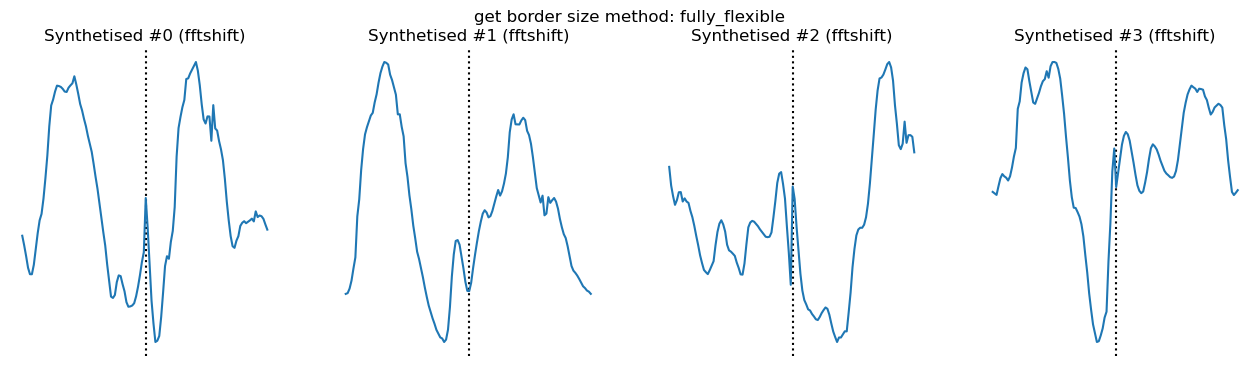

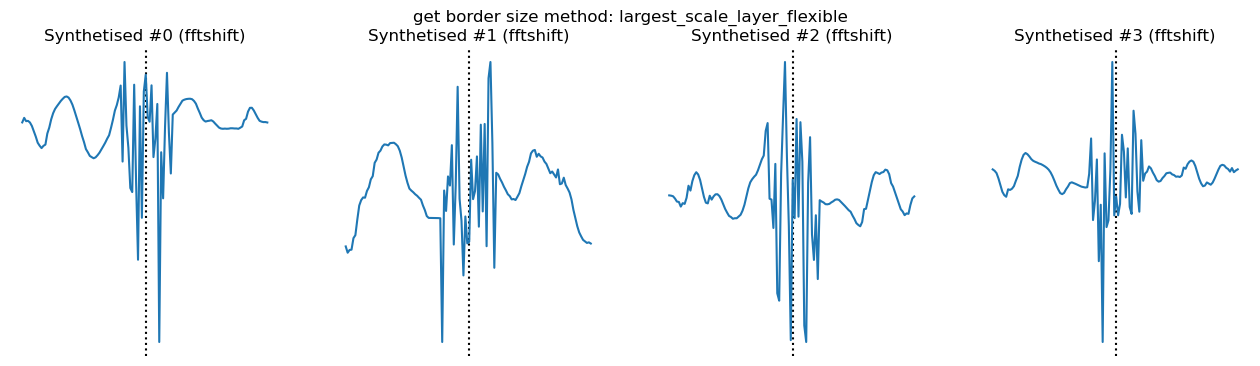

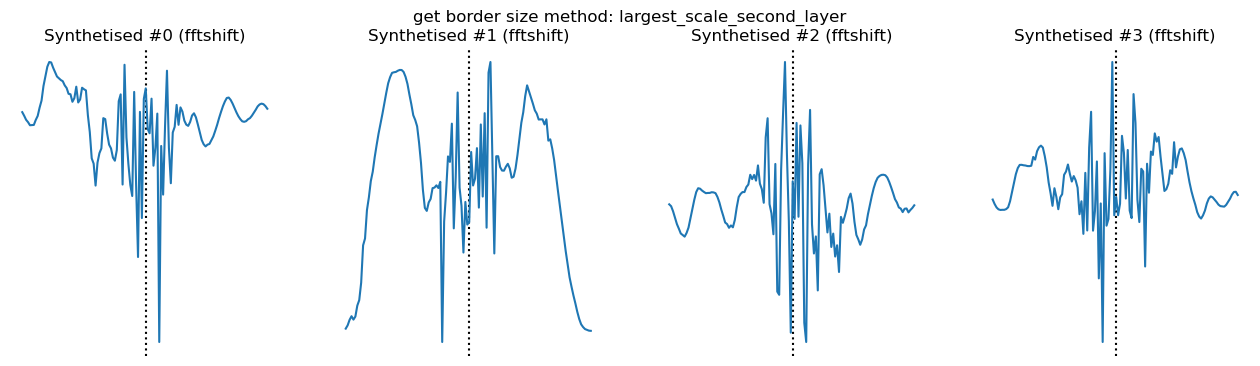

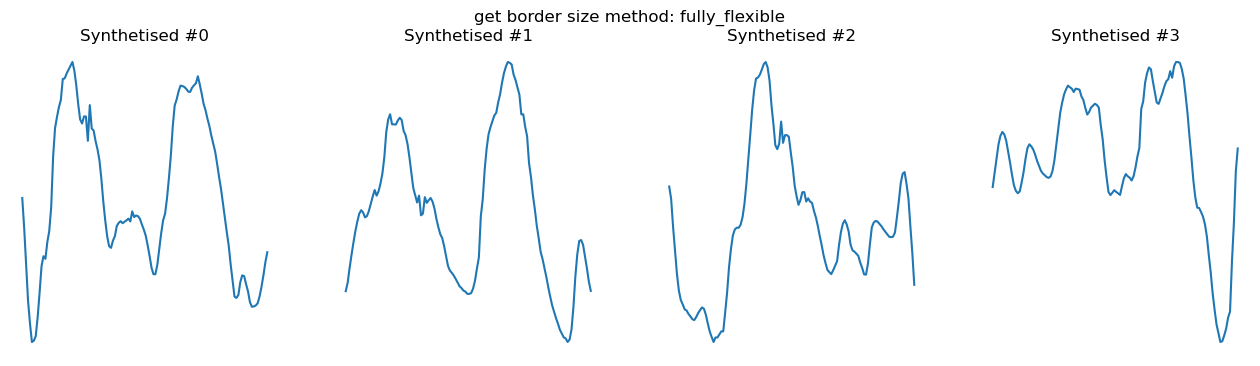

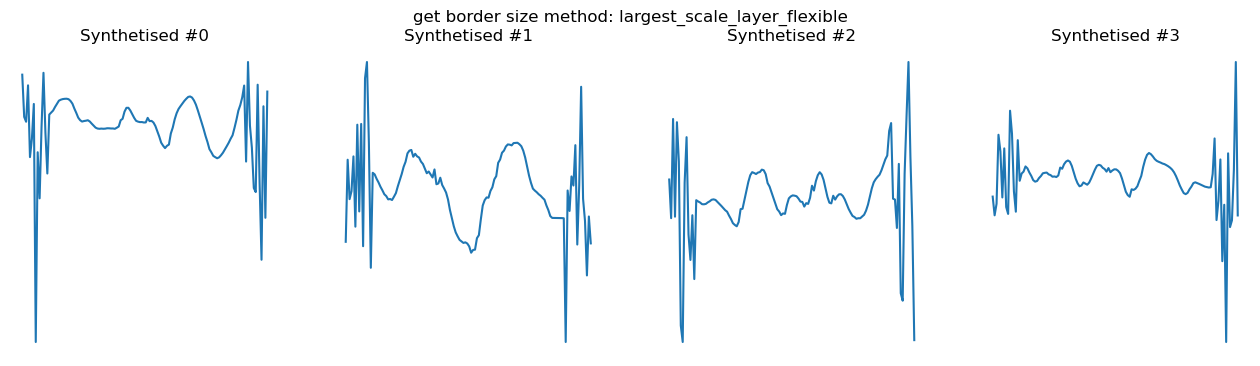

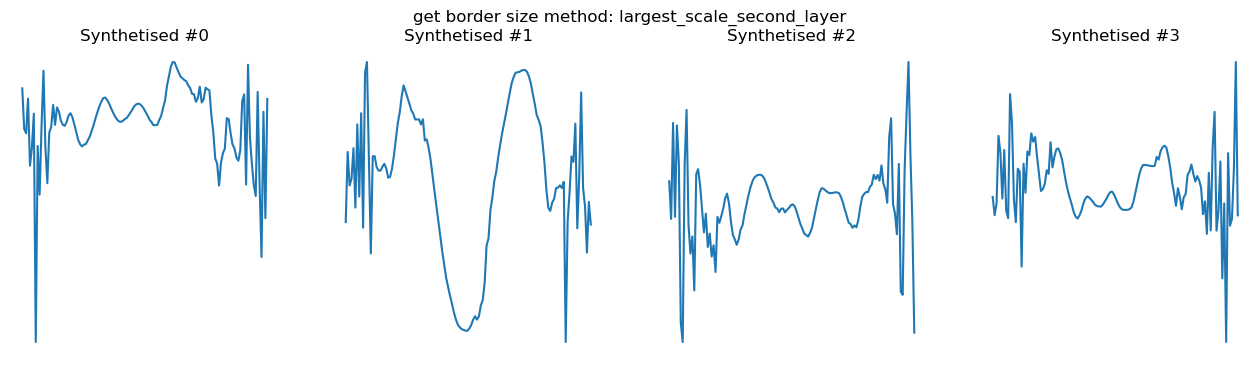

In [45]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.axvline(64, color='black', linestyle=':')
plt.plot(np.fft.fftshift(im[0,0,0,:128]))
plt.axis('off')
plt.title('Target (fftshift)')

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.axvline(64, color='black', linestyle=':')
        plt.plot(np.fft.fftshift(u[k].cpu().numpy()))
        plt.axis('off')
        plt.title('Synthetised #%d (fftshift)'%(k))

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.plot(u[k].cpu().numpy())
        plt.axis('off')
        plt.title('Synthetised #%d'%(k))

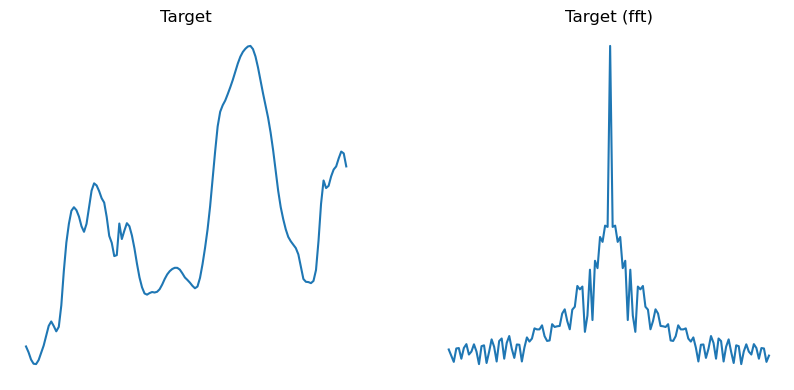

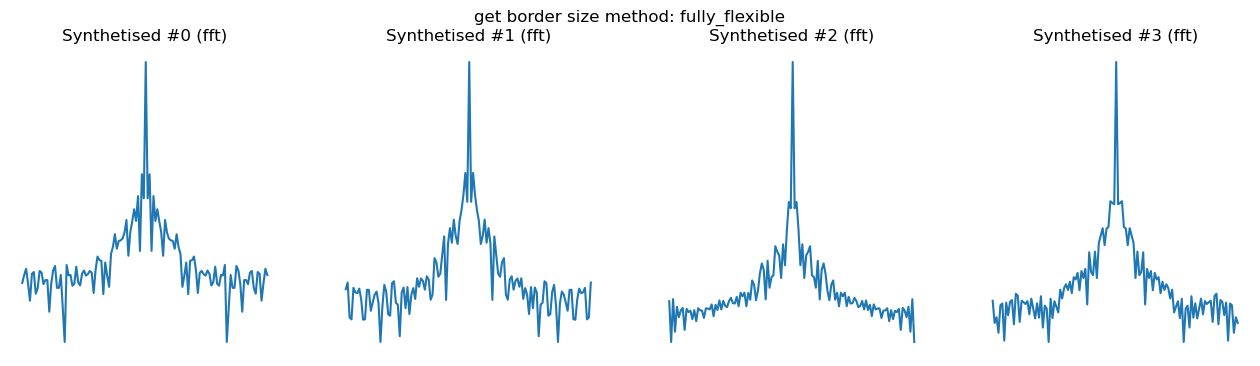

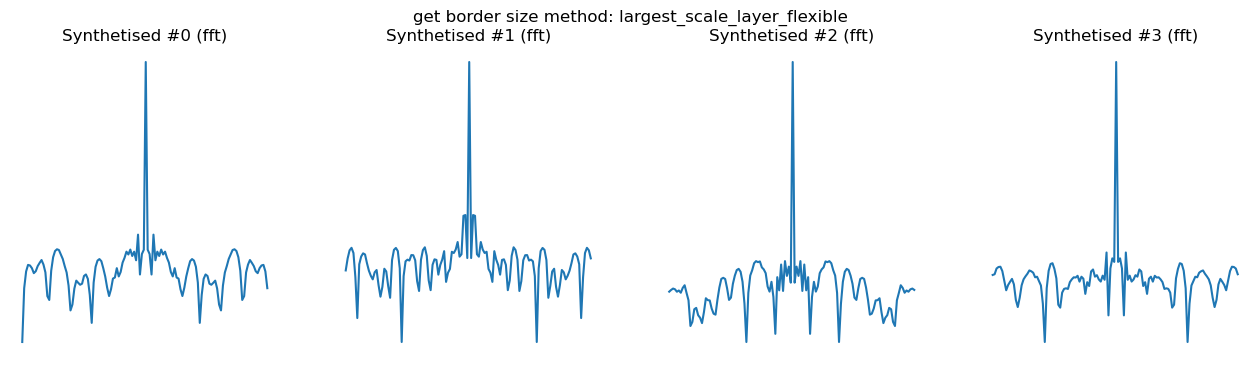

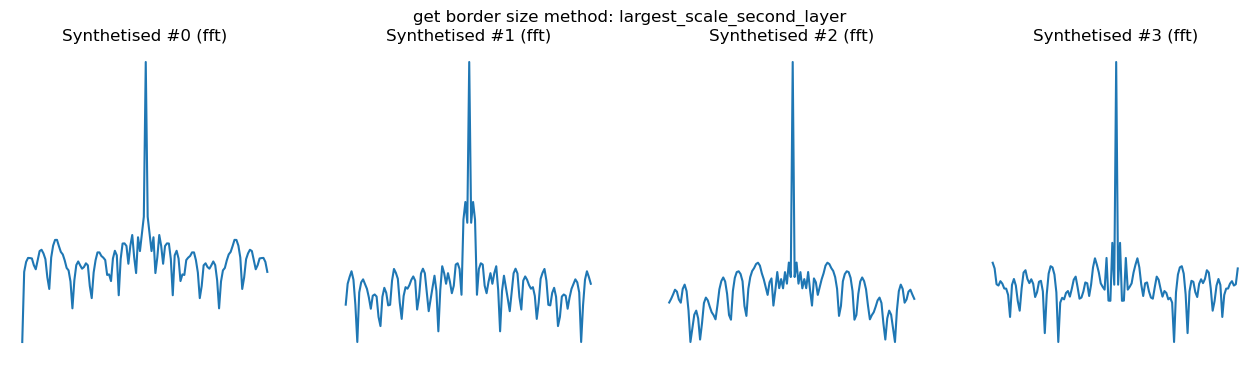

In [46]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.plot(im[0,0,0,:128])
plt.axis('off')
plt.title('Target')
plt.subplot(2,2,2)
plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(im[0,0,0,:128]))))
plt.axis('off')
plt.title('Target (fft)')

for method_name, u in synthesis_target_running_npbc_results.items():
    plt.figure(figsize=(16,4))
    plt.title('get border size method: %s\n'%method_name)
    plt.axis('off')
    for k in range(4):
        plt.subplot(1,4,1+k)
        plt.semilogy(np.abs(np.fft.fftshift(np.fft.fft(u[k].cpu().numpy()))))
        plt.axis('off')
        plt.title('Synthetised #%d (fft)'%(k))

### Littlewood-Paley and energy conservation (1D)

The kernel wavelet transform never builds the wavelet at scale $j$ explicitly: the 5-tap kernel $K$ is applied to the signal downsampled $j$ times by the anti-aliasing kernel $H$. Seen from the original grid, the effective filter at scale $j$ is

$$\hat\psi_j(f) = \hat K(2^j f)\,\prod_{i<j}\hat H(2^i f).$$

For a stationary signal of power spectrum $P$, the expected second-order coefficients are $S_2(j) = \int P(f)\,|\hat\psi_j(f)|^2\,df$, whatever the subsampling. The Littlewood-Paley sum $LP(f) = \sum_j |\hat\psi_j(f)|^2$ therefore tells which frequencies the scattering statistics see:
- energy is conserved, $\sum_j S_2(j) = \mathrm{Var}(x)$, when $LP(f) = 1$ on the band covered by the scales ($|f| > 2^{-J}/2$, the lower frequencies being described by the mean and the power spectrum);
- where $LP(f) \approx 0$, the statistics do not constrain the energy: a synthesis started from white noise keeps its initial energy there, unless the power spectrum is added to the loss.

kernel taps: [-0.0724+0.1614j -0.1257-0.2791j  0.3961-0.j     -0.1257+0.2791j
 -0.0724-0.1614j]
LP sum on the covered band: min 0.2564 at f = 0.500, mean 1.478, max 1.988
symmetry: max | |psi(f)| - |psi(-f)| | = 1.19e+00  (0 means not analytic)


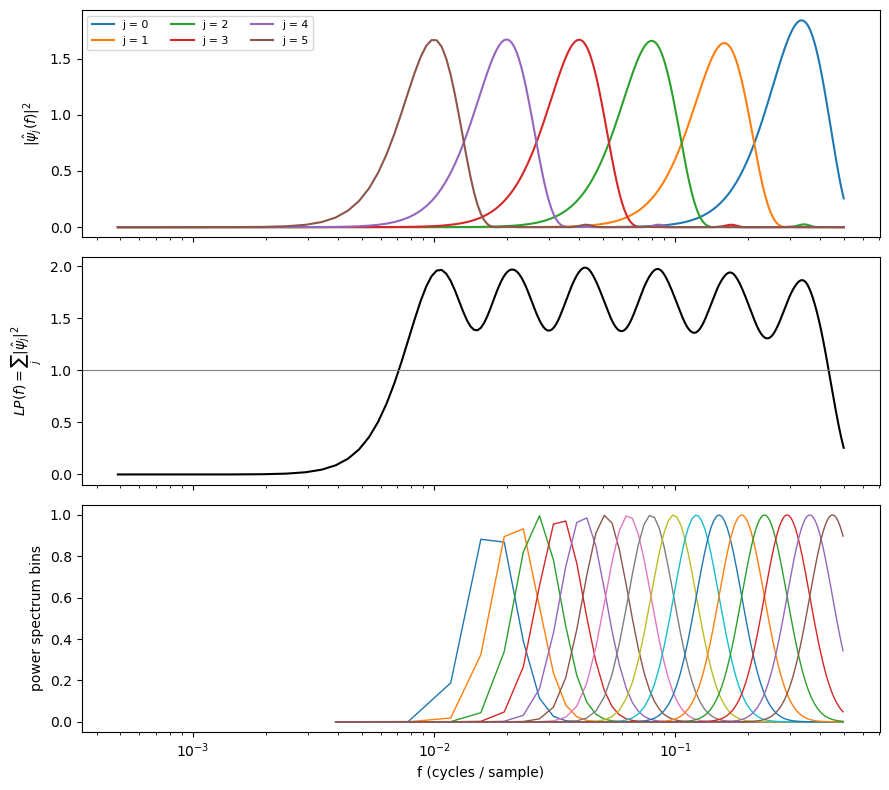

In [47]:
import torch

def effective_filters(w_op, N=2048):
    # |hat psi_j(f)| for j = 0..J-1 on the fftfreq grid of size N, from the kernels actually used by the operator
    K = w_op._wav_kernel[0, 0].detach().cpu().to(torch.complex128)
    H = w_op._get_smooth_kernel(device="cpu", dtype=torch.float64).to(torch.complex128)

    def dilated_fft(k, step):
        z = torch.zeros(N, dtype=torch.complex128)
        z[: len(k) * step : step] = k
        return torch.fft.fft(z)

    out, H_prod = [], torch.ones(N, dtype=torch.complex128)
    for j in range(w_op.J):
        out.append((dilated_fft(K, 2**j) * H_prod).abs())
        H_prod = H_prod * dilated_fft(H, 2**j)
    return torch.stack(out).numpy()  # [J, N]

lp_data = DataClass(im[0, 0, 0], pbc=True)
lp_w_op = lp_data.get_wavelet_op()
N_f = 2048
f = np.fft.fftfreq(N_f)
T = effective_filters(lp_w_op, N_f)
LP = (T**2).sum(0)
pos = f > 0
order = np.argsort(f[pos])
fp, Tp, LPp = f[pos][order], T[:, pos][:, order], LP[pos][order]

band = fp > 0.5 / 2**lp_w_op.J
i_min = np.argmin(LPp[band])
print("kernel taps:", lp_w_op._wav_kernel[0, 0].cpu().numpy().round(4))
print(f"LP sum on the covered band: min {LPp[band].min():.4f} at f = {fp[band][i_min]:.3f}, mean {LPp[band].mean():.3f}, max {LPp[band].max():.3f}")
print(f"symmetry: max | |psi(f)| - |psi(-f)| | = {np.abs(T - T[:, (-np.arange(N_f)) % N_f]).max():.2e}  (0 means not analytic)")

cs_op = lp_data.get_CS_op()
bins = cs_op.bin_masks.cpu().numpy()            # [n_bins, N] on the fftshifted grid of the signal
f_bins = np.fft.fftshift(np.fft.fftfreq(lp_data.array.shape[-1]))

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for j in range(lp_w_op.J):
    axes[0].plot(fp, Tp[j] ** 2, label=f"j = {j}")
axes[0].set_ylabel(r"$|\hat\psi_j(f)|^2$")
axes[0].legend(ncol=3, fontsize=8)
axes[1].plot(fp, LPp, color="k")
axes[1].axhline(1, color="gray", lw=0.8)
axes[1].set_ylabel(r"$LP(f)=\sum_j|\hat\psi_j|^2$")
for b in bins:
    axes[2].plot(f_bins[f_bins > 0], b[f_bins > 0], lw=1)
axes[2].set_ylabel("power spectrum bins")
axes[2].set_xlabel("f (cycles / sample)")
axes[2].set_xscale("log")
plt.tight_layout()
plt.show()

In [48]:
# Energy conservation: sum_j S2(j) / Var(x), measured with the ST operator and predicted from the LP sum.
def s2_energy_ratio(x):
    d = DataClass(x - x.mean(), pbc=True)
    st = d.get_ST_op(compute_PS=False).apply(d, norm="vanilla")
    s2 = st.S2.real.flatten().cpu().numpy()
    return s2.sum() / np.var(x)

rng = np.random.default_rng(0)
noise = rng.standard_normal(4096)
measured = s2_energy_ratio(noise)
predicted = LP.mean()  # white noise: flat spectrum
print(f"white noise : sum_j S2 / Var = {measured:.3f} (prediction from LP: {predicted:.3f})")

x = im[0, 0, 0]
Px = np.abs(np.fft.fft(x - x.mean(), n=N_f)) ** 2
print(f"target row  : sum_j S2 / Var = {s2_energy_ratio(x):.3f} (prediction from LP: {(Px * LP).sum() / Px.sum():.3f})")

white noise : sum_j S2 / Var = 0.814 (prediction from LP: 0.799)
target row  : sum_j S2 / Var = 0.665 (prediction from LP: 0.714)


Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 107 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
309 iterations of synthesis.
Execution time: 115.522 s
Running synthesis on device: mps:0 dtype: torch.float32
Initial shape for u: (4, 1, 256)
Prefiltering target to remove frequencies above Nyquist
Synthesis on 91 ST coefficients
Prefiltering initial map to remove frequencies above Nyquist
310 iterations of synthesis.
Execution time: 96.485 s
band          ratio with PS   ratio without PS   min LP in band
(0.00,0.05]           1.00               1.03            0.000
(0.05,0.10]           0.89               0.88            1.378
(0.10,0.20]           0.97               0.96            1.362
(0.20,0.30]           1.14               0.75            1.309
(0.30,0.38]           1.03               1.01            1.628
(0.38,0.45]           0.99         

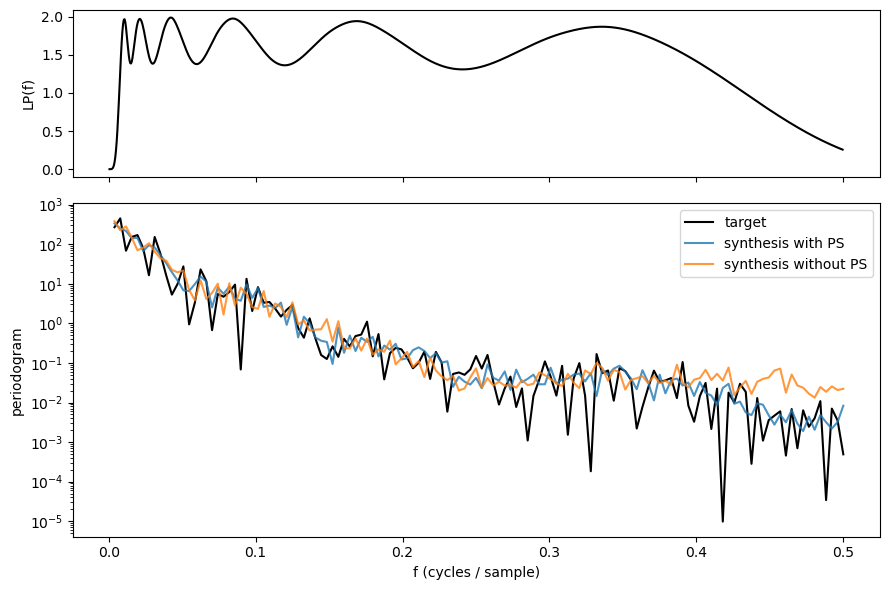

In [49]:
# Same synthesis as above, with and without the power spectrum in the loss
from STL_main.Synthesis import synthesize_from_maps
seed = 42
target_lp = DataClass(im[0, 0, 0], pbc=True)
u_ps = synthesize_from_maps(target_lp, pbc_running=True, nbatch=4, max_iter=300, seed=seed, verbose=False)
u_nops = synthesize_from_maps(target_lp, pbc_running=True, nbatch=4, max_iter=300, seed=seed, verbose=False, compute_PS=False)

def periodogram(a):
    a = np.atleast_2d(np.asarray(a))
    a = a - a.mean(-1, keepdims=True)
    return (np.abs(np.fft.rfft(a, axis=-1)) ** 2).mean(0)

x = im[0, 0, 0]
fr = np.fft.rfftfreq(len(x))
P_t, P_ps, P_nops = periodogram(x), periodogram(u_ps.cpu().numpy()), periodogram(u_nops.cpu().numpy())

print("band          ratio with PS   ratio without PS   min LP in band")
for lo, hi in [(0, 0.05), (0.05, 0.1), (0.1, 0.2), (0.2, 0.3), (0.3, 0.38), (0.38, 0.45), (0.45, 0.51)]:
    s = (fr > lo) & (fr <= hi)
    lp_min = LPp[(fp > lo) & (fp <= hi)].min()
    print(f"({lo:.2f},{hi:.2f}]   {P_ps[s].sum() / P_t[s].sum():12.2f}   {P_nops[s].sum() / P_t[s].sum():16.2f}   {lp_min:14.3f}")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
axes[0].plot(fp, LPp, color="k")
axes[0].set_ylabel("LP(f)")
axes[1].semilogy(fr[1:], P_t[1:], label="target", color="k")
axes[1].semilogy(fr[1:], P_ps[1:], label="synthesis with PS", alpha=0.8)
axes[1].semilogy(fr[1:], P_nops[1:], label="synthesis without PS", alpha=0.8)
axes[1].set_xlabel("f (cycles / sample)")
axes[1].set_ylabel("periodogram")
axes[1].legend()
plt.tight_layout()
plt.show()

In [50]:
# The global amplitude c of the kernel is not neutral: after normalization by S2_ref,
# S1 and S2 are unchanged, but S3 scales as c and S4 as c^2, exactly like the ad hoc weights of the synthesis.
d = DataClass(im[0, 0, 0], pbc=True)
ref = {}
for c in (1.0, 2.0):
    op = d.get_ST_op(compute_PS=False)
    op.wavelet_op._wav_kernel = op.wavelet_op._wav_kernel * c
    st = op.apply(d.copy(), norm="store_ref")
    ref[c] = {k: getattr(st, k) for k in ["S1", "S2", "S3", "S4"]}
for k in ["S1", "S2", "S3", "S4"]:
    a, b = ref[1.0][k], ref[2.0][k]
    ok = ~(a.isnan() | b.isnan()) & (a.abs() > 0)
    print(f"{k}: median ratio (c=2 / c=1) = {(b[ok] / a[ok]).abs().median().item():.3f}")

S1: median ratio (c=2 / c=1) = 1.000
S2: median ratio (c=2 / c=1) = 1.000
S3: median ratio (c=2 / c=1) = 2.000
S4: median ratio (c=2 / c=1) = 4.000


**Reading of these results**

- The spurious high-frequency energy of the syntheses comes from a blind band of the wavelet frame: the LP sum nearly vanishes around $f \approx 0.42$ cycle per sample. The current 5-tap kernel has a zero there, and every coarser scale is cut by the anti-aliasing kernel ($|\hat H(0.375)| \approx 0.18$, $\hat H(1/2) = 0$), so no filter covers this band. The scattering statistics are blind to it, and white-noise energy survives there.
- When the power spectrum is in the loss (default of `synthesize_from_maps` when there are no NaNs), its Gaussian bins reach the Nyquist frequency and remove most of this energy. All the syntheses that use `optimize_from_maps` without `compute_PS=True`, or that contain NaNs (power spectrum disabled), keep it.
- Energy is not conserved either on average: the LP sum stays well below 1 on the whole band, so $\sum_j S_2(j)$ captures only part of the variance.
- The amplitude of the kernel (`kernel *= 4.0`) is not neutral: it changes the relative weight of $S_3$ (as $c$) and $S_4$ (as $c^2$) in the loss, exactly like the ad hoc weights $3.5$ and $3.5^2$. A principled choice is to scale the kernel so that the LP sum equals 1 on the covered band, which is the convention of the 2D Fourier wavelets, so that the 2D ad hoc weights keep the same meaning in 1D.
- The new kernel (central column of the first 2D orientation) is real and symmetric, so it is still not analytic. The analytic profile is the central row, `kernel[:, :1, w, :]`.